# Canteen Food Waste Forecasting with a Stacking Ensemble (Kaggle Canteen Dataset, Improved Method)

This notebook is a modified copy of `kaggle_canteen_methodology.ipynb`. It uses the same models (Random Forest, XGBoost, SVR, LSTM and two stacking ensembles) with the same settings, but prepares the data so that the models never see information from the test period or from the value they are predicting. It also adds descriptive statistics and evaluation metrics, reduces the training time of the stacking ensembles and explains their forecasts. Changed lines in the code are marked `# CHANGED:`.

Before any modelling, Section 1 checks the data quality: missing values, duplicate records, category labels, invalid values, consistency between columns, outliers and how complete the daily records are. The only change needed is that `Month` is not used as an input, because the data covers only 61 days.

The forecasts are one record ahead: each record is predicted from the waste of the earlier records of the same series (the lag inputs), the meal, canteen section, food category, calendar and unit price, which are assumed to be known in advance. Forecasting further ahead would need lag inputs that end earlier.

Changes from `kaggle_canteen_methodology.ipynb`:
1. `Cost_Loss` is no longer used as an input (Section 0).
2. Descriptive statistics and histograms of the numeric variables are added (Section 3).
3. The data is split by date instead of at random: the first 80 % of days for training and the last 20 % for testing (Section 4).
4. Missing lag values are filled with training-set means after the split, instead of full-data means before it (Sections 2 and 4).
5. MSE, RMSE and SMAPE are added to the metrics (Section 5).
6. The LSTM is tested on the same rows as the other models and trains only on rows with a full 10-record history (Section 7).
7. The stacking meta-learner is tuned with `RidgeCV` instead of a grid search that retrains the whole stack (Sections 8 and 9).
8. A new section compares the training time and accuracy of both tuning methods (Section 11).
9. A new section explains the forecasts of both stacking ensembles with SHAP and LIME (Section 12).
10. A naive baseline (the previous record of the same series) is added to the results as a reference point (Section 5).
11. Stacking 2's LSTM is retrained in every cross-validation fold instead of being trained once and reused (Section 9).
12. A paired significance test checks whether the stacking ensembles' errors differ from the best single model's (Section 10).

| Section | Content |
|---|---|
| 0 | Setup: dataset location, libraries, configuration |
| 1 | Data loading and data quality checks |
| 2 | Feature engineering: date features and lagged waste |
| 3 | Data analysis and descriptive statistics |
| 4 | One-hot encoding, train/test split by date, imputation, scaling |
| 5 | Evaluation metrics |
| 6 | Random Forest, XGBoost and SVR with grid search |
| 7 | LSTM |
| 8 | Stacking 1: RF + XGBoost + SVR → Ridge |
| 9 | Stacking 2: RF + XGBoost + SVR + LSTM → Ridge |
| 10 | Results and plots |
| 11 | Stacking training time vs accuracy |
| 12 | Explainability: SHAP and LIME |

## 0. Setup
This section locates the dataset, imports the libraries and sets the configuration used throughout the notebook.

In [1]:
# Locate the dataset. Move to the repository's main folder (the folder that holds datasets/), so the paths below
# work wherever the notebook is opened. On Google Colab, where the repository is not present yet, it is cloned first.
import os, sys
from pathlib import Path
GITHUB_USER = "yklee7285"                     # GitHub account that hosts the public repository
REPO        = "food-demand-forecasting-fyp"
DATA_PATH   = "datasets/canteen_dataset.csv"

root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets").is_dir()), None)
if root is not None:
    os.chdir(root)
elif "google.colab" in sys.modules:
    if not os.path.isdir(REPO):
        !git clone -q https://github.com/{GITHUB_USER}/{REPO}.git
    %cd {REPO}

In [2]:
# Standard library; hide warnings and TensorFlow start-up logs
import time, random, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# Data handling, plotting and statistical tests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# scikit-learn: splitting, tuning, scaling, models and metrics
from sklearn.model_selection import GridSearchCV   # CHANGED: train_test_split removed because the split is now by date
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge, RidgeCV   # CHANGED: RidgeCV added for the stacking meta-learner
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score   # CHANGED: mean_squared_error added for MSE and RMSE
from xgboost import XGBRegressor

# TensorFlow / Keras for the LSTM
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
tf.get_logger().setLevel("ERROR")
sns.set_style("whitegrid")

# ---------------- Configuration ----------------
RANDOM_STATE      = 42        # seed for the tree models and the LSTM (CHANGED: no longer used for the split)
TEST_SIZE         = 0.20      # share of days held out for testing
CV_FOLDS          = 5         # folds for grid-search cross-validation and stacking
SCORING           = "neg_mean_absolute_error"   # grid search keeps the parameters with the lowest MAE
SEQ_LEN           = 10        # LSTM input length: the 10 preceding records of the same series
WEEK_RECORDS      = 7         # one week of daily records for the weekly lag
USE_COST_LOSS     = False     # CHANGED: was True. Cost_Loss is waste x price per kg, so it contains the target and is not known in advance
LSTM_SCALE_TARGET = True      # LSTM learns a 0-1 scaled target; predictions are converted back to kg
SVR_TARGET_SD     = 9.63      # SVR learns the target rescaled to this standard deviation; predictions are converted back to kg
RIDGE_GRID        = {"alpha": [0.01, 0.1, 1, 10, 100]}   # alpha values tested for the Ridge meta-learner
SHAP_ROWS         = 100       # CHANGED: new setting. Number of test rows explained with SHAP (chosen at random)
TARGET            = "Waste_Weight_kg"                   # column being forecast
SERIES            = ["Meal", "Canteen_Section", "Food_Category"]   # one series per combination
UNIT              = "kg"                                # unit of the target, for labels

def set_seeds(seed=RANDOM_STATE):
    # Fix the Python, NumPy and TensorFlow random generators so results are repeatable
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)
set_seeds()

I0000 00:00:1794911085.951009   13708 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794911087.388391   13708 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Data loading and data quality
This loads the dataset and sorts it by date and series, then checks its quality before any modelling.

In [3]:
df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"])
# Lag features and LSTM windows rely on chronological order within each meal, section and food category
df = df.sort_values(["Date"] + SERIES).reset_index(drop=True)
print("Rows:", len(df), "| Days:", df.Date.nunique(), "| Range:", df.Date.min().date(), "to", df.Date.max().date(),
      "| Series (meal x section x food category):", df.groupby(SERIES).ngroups)
display(df.head())

Rows: 2600 | Days: 61 | Range: 2025-06-11 to 2025-08-10 | Series (meal x section x food category): 48


,Date,Meal,Canteen_Section,Food_Category,Waste_Weight_kg,Unit_Price_per_kg,Cost_Loss
0,2025-06-11,Breakfast,A,Rice,4.59,2.0,9.18
1,2025-06-11,Breakfast,A,Soup,3.21,1.5,4.81
2,2025-06-11,Breakfast,A,Vegetables,2.97,3.0,8.91
3,2025-06-11,Breakfast,B,Meat,0.55,8.0,4.40
4,2025-06-11,Breakfast,B,Rice,2.51,2.0,5.02


### Data quality checks
The checks cover missing values, duplicate records, category labels, invalid values, consistency between columns, outliers (1.5 x IQR rule) and how complete the daily records are. Findings and how they are handled:
- No missing values, duplicates, inconsistent labels or invalid values, and no outliers in waste, so no rows are removed or changed.
- The Cost_Loss outliers are all Meat, the most expensive category, so they are real values. Cost_Loss is waste x price, so it contains the target.
- Each food category has a single price, so `Unit_Price_per_kg` repeats the information in `Food_Category`.
- About 11 % of the day x series combinations have no record. The file does not say whether this means no waste or no record, so they are left missing rather than filled with an assumed value. The lags therefore use the previous recorded day of each series.
- The data covers only 61 days (June to August 2025), so `Month` is not used as an input: it cannot capture seasonality over such a short period, and with a split by date the last month would not appear in the training set.

In [4]:
NUMERIC_RAW = [TARGET, "Unit_Price_per_kg", "Cost_Loss"]

# Missing values, duplicates and category labels
print("Missing values (expect 0):", df.isna().sum().sum())
print("Duplicate rows (expect 0):", df.duplicated().sum(), "| Same day and series recorded twice (expect 0):", df.duplicated(["Date"] + SERIES).sum())
print("Category labels:", {c: sorted(df[c].unique()) for c in SERIES})

# Invalid values and consistency between columns
print("Waste range (kg):", df[TARGET].min(), "to", df[TARGET].max(), "| zero or negative (expect 0):", (df[TARGET] <= 0).sum())
print("Cost_Loss differing from waste x price by more than rounding (expect 0):",
      ((df[TARGET] * df.Unit_Price_per_kg - df.Cost_Loss).abs() > 0.011).sum())
print("Prices per food category (one price each means the price repeats Food_Category):",
      df.groupby("Food_Category").Unit_Price_per_kg.unique().apply(lambda v: [float(x) for x in v]).to_dict())

# Outliers by the 1.5 x IQR rule
q1, q3 = df[NUMERIC_RAW].quantile(0.25), df[NUMERIC_RAW].quantile(0.75)
outlier = (df[NUMERIC_RAW] < q1 - 1.5 * (q3 - q1)) | (df[NUMERIC_RAW] > q3 + 1.5 * (q3 - q1))
print("Outliers (1.5 x IQR):", outlier.sum().to_dict(), "| Cost_Loss outliers by food category:",
      df[outlier.Cost_Loss].Food_Category.value_counts().to_dict())

# Coverage: days without records and combinations missing on a day
days = pd.date_range(df.Date.min(), df.Date.max())
n_grid = len(days) * df.groupby(SERIES).ngroups
per_day = df.groupby("Date").size()
print("Days without any record (expect 0):", len(days.difference(df.Date.unique())))
print(f"Recorded rows: {len(df)} of {n_grid} day x series combinations ({len(df) / n_grid:.1%});",
      f"series recorded per day: {per_day.min()} to {per_day.max()} of {df.groupby(SERIES).ngroups}")

Missing values (expect 0): 0
Duplicate rows (expect 0): 0 | Same day and series recorded twice (expect 0): 0
Category labels: {'Meal': ['Breakfast', 'Dinner', 'Lunch'], 'Canteen_Section': ['A', 'B', 'C', 'D'], 'Food_Category': ['Meat', 'Rice', 'Soup', 'Vegetables']}
Waste range (kg): 0.1 to 5.0 | zero or negative (expect 0): 0
Cost_Loss differing from waste x price by more than rounding (expect 0): 0
Prices per food category (one price each means the price repeats Food_Category): {'Meat': [8.0], 'Rice': [2.0], 'Soup': [1.5], 'Vegetables': [3.0]}
Outliers (1.5 x IQR): {'Waste_Weight_kg': 0, 'Unit_Price_per_kg': 0, 'Cost_Loss': 291} | Cost_Loss outliers by food category: {'Meat': 291}
Days without any record (expect 0): 0
Recorded rows: 2600 of 2928 day x series combinations (88.8%); series recorded per day: 37 to 46 of 48


## 2. Feature engineering
This adds model inputs derived from the date and from past waste. Each combination of meal, canteen section and food category is treated as its own series, and the lags only use earlier records of the same series:
* `Day_of_Week` and `Weekend_Status` (Saturday and Sunday).
* `Waste_last_day`: waste at the previous record of the series.
* `Waste_last_two_days`: total waste over the previous 2 records.
* `Waste_last_week`: total waste over the previous 7 records.

Not every combination is recorded every day, so a "record" is the previous day on which that combination appears.

`Week_of_Month` is created only for the check in Section 3 and is not a model input. The first records of each series have no history for the lags. Those gaps are filled in Section 4, after the split, using training-set means.

In [5]:
df["Day_of_Week"]    = df.Date.dt.day_name()
df["Weekend_Status"] = np.where(df.Date.dt.dayofweek >= 5, "Weekend", "Weekday")
df["Week_of_Month"]  = (df.Date.dt.day - 1) // 7 + 1           # 1-5; used only for the check in Section 3

# Lagged waste within each series: shifting by one record first ensures a row's own waste never enters its lags
g = df.groupby(SERIES)[TARGET]
df["Waste_last_day"]      = g.shift(1)                                                   # previous record
df["Waste_last_two_days"] = g.transform(lambda s: s.shift(1).rolling(2).sum())
df["Waste_last_week"]     = g.transform(lambda s: s.shift(1).rolling(WEEK_RECORDS).sum())

# The first records of each series have no history yet; they are filled in Section 4
LAG_COLS = ["Waste_last_day", "Waste_last_two_days", "Waste_last_week"]
print("Missing lag values (filled in Section 4):", df[LAG_COLS].isna().sum().to_dict())
# CHANGED: missing values are no longer filled here, because full-data means include test-period values
display(df.loc[df.groupby(SERIES).ngroup() == 0, ["Date"] + SERIES + [TARGET] + LAG_COLS].head(8))   # first records of one series

Missing lag values (filled in Section 4): {'Waste_last_day': 48, 'Waste_last_two_days': 96, 'Waste_last_week': 336}


,Date,Meal,Canteen_Section,Food_Category,Waste_Weight_kg,Waste_last_day,Waste_last_two_days,Waste_last_week
44,2025-06-12,Breakfast,A,Meat,2.54,NaN,NaN,NaN
90,2025-06-13,Breakfast,A,Meat,4.36,2.54,NaN,NaN
134,2025-06-14,Breakfast,A,Meat,4.57,4.36,6.90,NaN
177,2025-06-15,Breakfast,A,Meat,1.61,4.57,8.93,NaN
264,2025-06-17,Breakfast,A,Meat,1.16,1.61,6.18,NaN
354,2025-06-19,Breakfast,A,Meat,3.84,1.16,2.77,NaN
396,2025-06-20,Breakfast,A,Meat,0.32,3.84,5.00,NaN
438,2025-06-21,Breakfast,A,Meat,1.81,0.32,4.16,18.4


## 3. Data analysis
This summarises the numeric variables with descriptive statistics and histograms, plots how waste varies with the main inputs, then tests whether week of the month has any effect on waste. The test is a one-way ANOVA: p > 0.05 means no meaningful effect, so week of the month is not used as an input.

### Descriptive statistics
Count, mean, standard deviation, range, skewness and kurtosis of each numeric variable, followed by their histograms. Skewness measures asymmetry (0 means symmetric) and kurtosis measures how heavy the tails are (0 is the same as a normal distribution). The missing counts are the lag values at the start of each series.

,count,mean,std,min,25%,50%,75%,max,missing,skewness,kurtosis
Waste_Weight_kg,2600.0,2.586,1.408,0.10,1.390,2.600,3.800,5.00,0,-0.035,-1.191
Unit_Price_per_kg,2600.0,3.635,2.585,1.50,2.000,3.000,8.000,8.00,0,1.005,-0.800
Cost_Loss,2600.0,9.233,8.952,0.15,3.495,6.360,10.950,40.00,0,1.752,2.430
Waste_last_day,2552.0,2.583,1.409,0.10,1.388,2.590,3.800,5.00,48,-0.031,-1.189
Waste_last_two_days,2504.0,5.157,2.006,0.40,3.758,5.150,6.580,9.91,96,-0.005,-0.570
Waste_last_week,2264.0,18.004,3.783,6.49,15.468,18.125,20.632,29.09,336,-0.127,-0.083


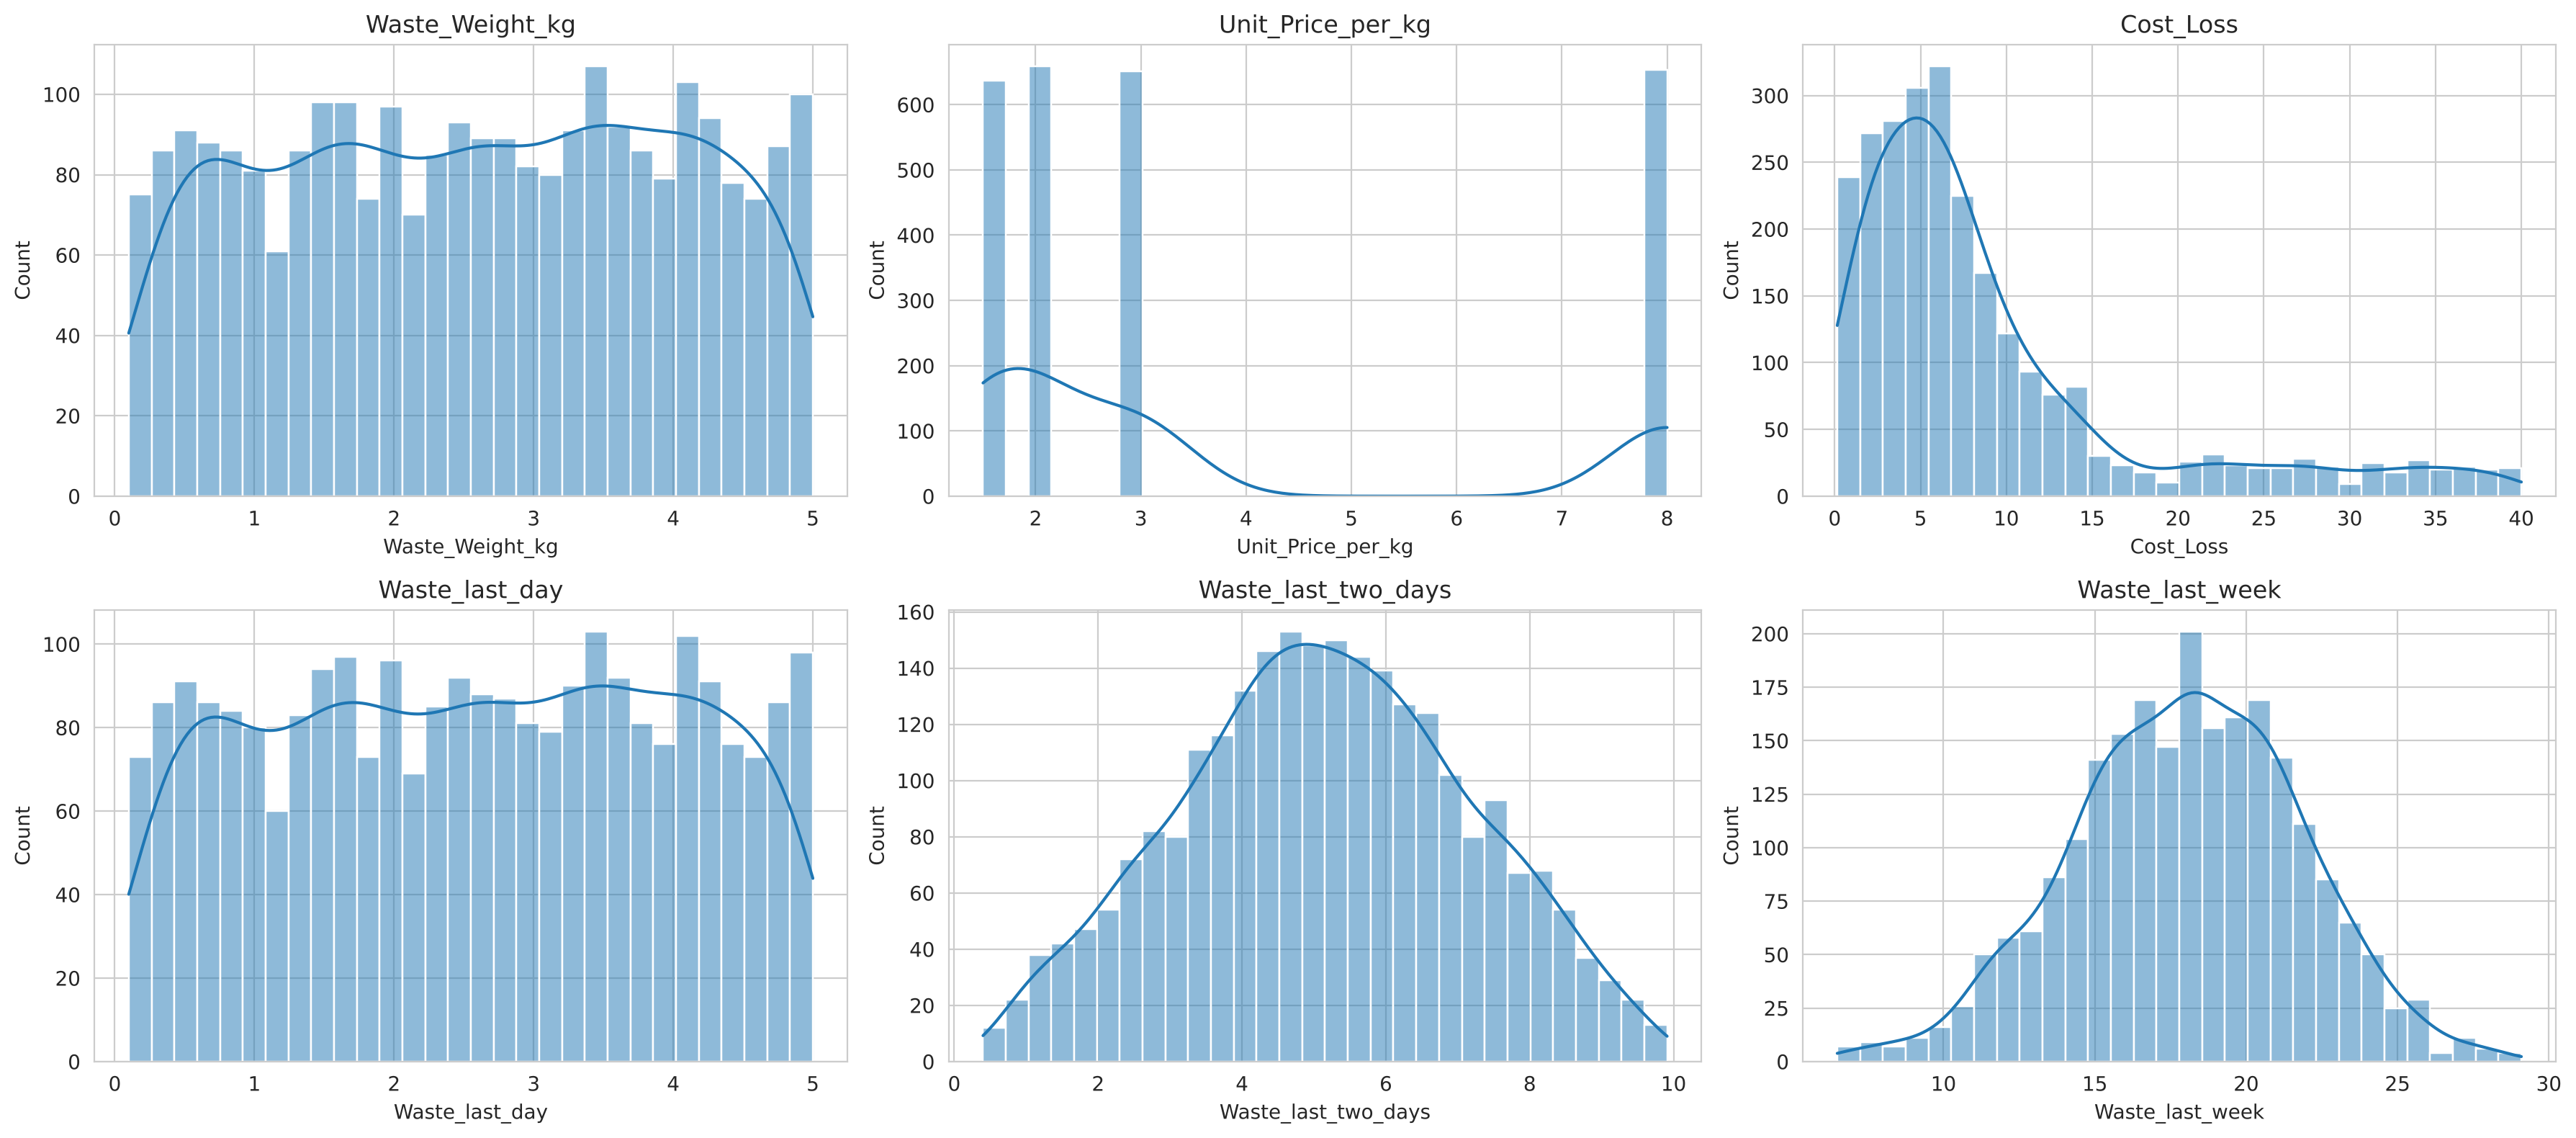

In [6]:
# CHANGED: new cell for descriptive statistics and histograms of the numeric variables
NUMERIC = [TARGET, "Unit_Price_per_kg", "Cost_Loss"] + LAG_COLS
desc = df[NUMERIC].describe().T                      # count, mean, std, min, quartiles, max
desc["missing"]  = df[NUMERIC].isna().sum()
desc["skewness"] = df[NUMERIC].skew()
desc["kurtosis"] = df[NUMERIC].kurt()                # excess kurtosis, 0 for a normal distribution
display(desc.round(3))

# Histogram of each numeric variable
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for a, col in zip(axes.ravel(), NUMERIC):
    sns.histplot(df[col].dropna(), bins=30, kde=True, ax=a).set_title(col)
plt.tight_layout(); plt.show()

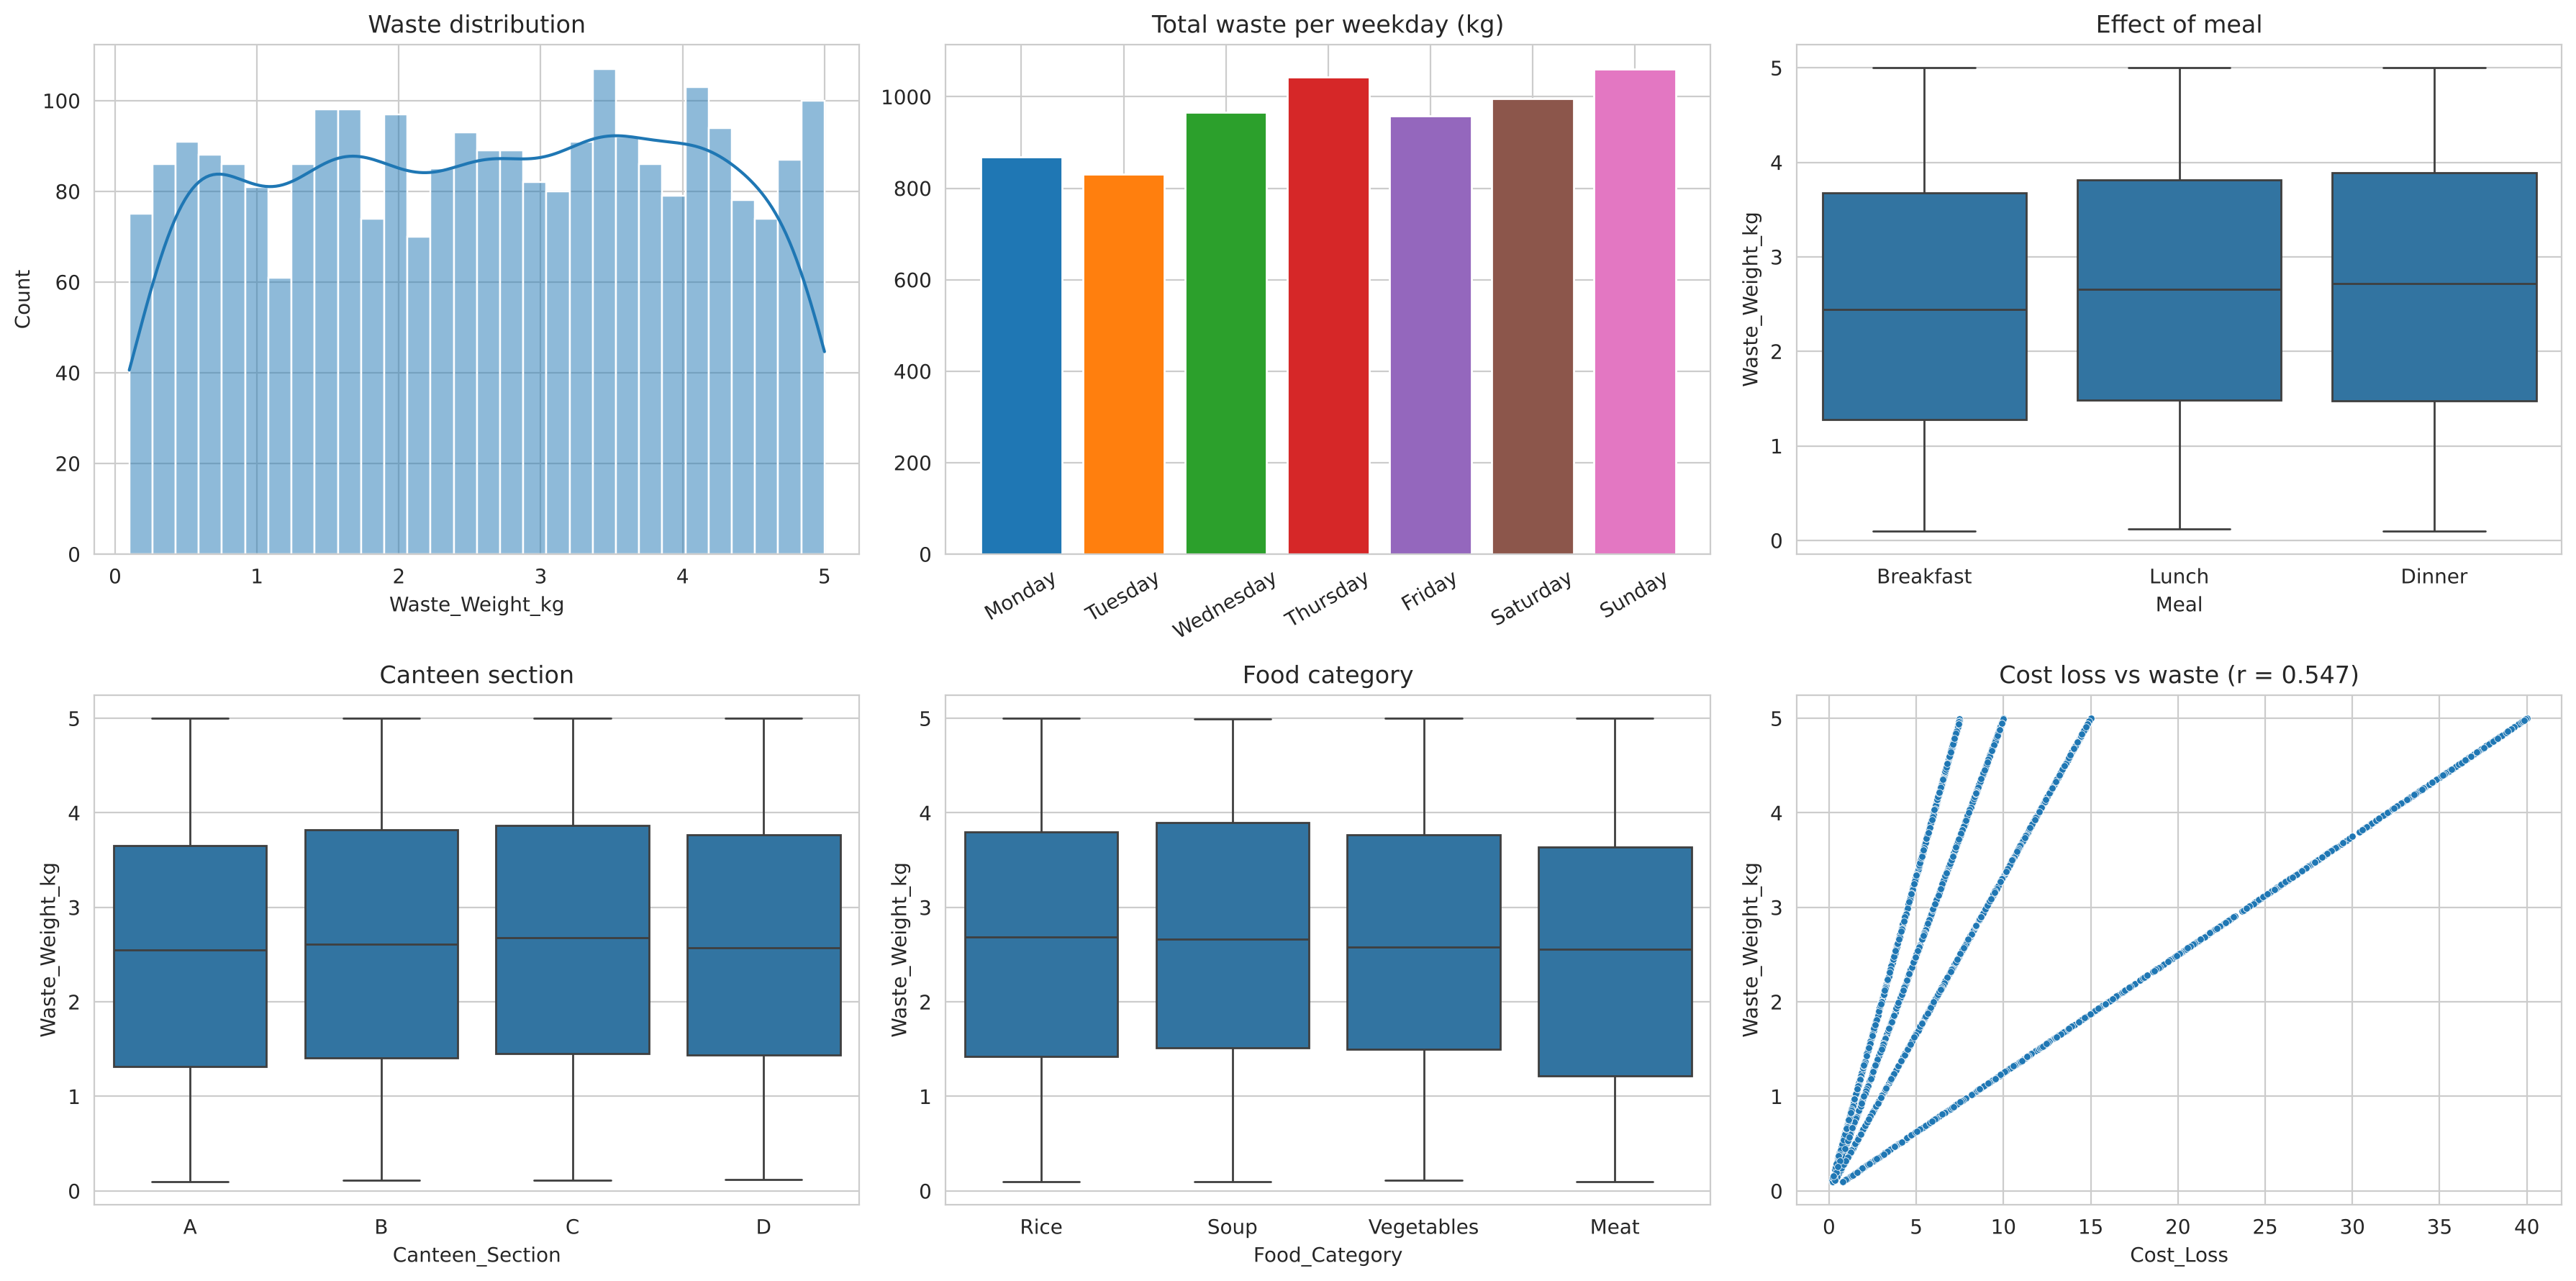

Week-of-month ANOVA: F = 1.221, p = 0.300 -> excluded (no meaningful effect)


In [7]:
DAYS  = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
MEALS = ["Breakfast", "Lunch", "Dinner"]
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
# Distribution of waste per record
sns.histplot(df[TARGET], bins=30, kde=True, ax=ax[0, 0]).set_title("Waste distribution")
# Total waste on each weekday
ax[0, 1].bar(DAYS, df.groupby("Day_of_Week")[TARGET].sum().reindex(DAYS), color=sns.color_palette("tab10", 7))
ax[0, 1].set_title("Total waste per weekday (kg)"); ax[0, 1].tick_params(axis="x", rotation=30)
# Waste by meal, canteen section and food category
sns.boxplot(data=df, x="Meal", y=TARGET, order=MEALS, ax=ax[0, 2]).set_title("Effect of meal")
sns.boxplot(data=df, x="Canteen_Section", y=TARGET, order=sorted(df.Canteen_Section.unique()), ax=ax[1, 0]).set_title("Canteen section")
sns.boxplot(data=df, x="Food_Category", y=TARGET, ax=ax[1, 1]).set_title("Food category")
# Cost loss against waste, with their correlation in the title
sns.scatterplot(data=df, x="Cost_Loss", y=TARGET, s=12, ax=ax[1, 2]).set_title(
    f"Cost loss vs waste (r = {df[['Cost_Loss', TARGET]].corr().iloc[0, 1]:.3f})")
plt.tight_layout(); plt.show()

# One-way ANOVA: does mean waste differ between weeks of the month?
f, p = stats.f_oneway(*[g[TARGET].values for _, g in df.groupby("Week_of_Month")])
print(f"Week-of-month ANOVA: F = {f:.3f}, p = {p:.3f} -> {'excluded (no meaningful effect)' if p > 0.05 else 'significant'}")

## 4. Encoding, split, imputation and scaling
1. Categorical inputs are one-hot encoded (one 0/1 column per category).
2. Rows are split by date: the first 80 % of days form the training set and the last 20 % the test set, so every model is trained on earlier days and tested on later ones. The split is made on row numbers so the LSTM windows use the same training and test rows.
3. Missing lag values are filled with the training-set mean of each lag column.
4. Inputs are scaled to 0–1 with a scaler fitted on the training rows only, so no test information enters training. The target stays in kg.

In [8]:
CAT_COLS = ["Meal", "Canteen_Section", "Food_Category", "Day_of_Week", "Weekend_Status"]
NUM_COLS = ["Unit_Price_per_kg"] + (["Cost_Loss"] if USE_COST_LOSS else []) + LAG_COLS

X = pd.get_dummies(df[CAT_COLS + NUM_COLS], columns=CAT_COLS, dtype=float)    # one-hot encode the categorical columns
y = df[TARGET].to_numpy(dtype=float)

# CHANGED: split by date instead of at random, so no training row comes after a test row
dates  = np.sort(df.Date.unique())
cutoff = dates[-int(np.ceil(len(dates) * TEST_SIZE))]          # first test day: the last 20 % of days are the test period
idx_tr, idx_te = np.where(df.Date < cutoff)[0], np.where(df.Date >= cutoff)[0]
print("Train:", df.Date.iloc[idx_tr[0]].date(), "to", df.Date.iloc[idx_tr[-1]].date(), f"({len(idx_tr)} rows)",
      "| Test:", df.Date.iloc[idx_te[0]].date(), "to", df.Date.iloc[idx_te[-1]].date(), f"({len(idx_te)} rows)")

# CHANGED: missing lag values filled with training-set means (previously full-data means before the split)
X = X.fillna(X.iloc[idx_tr].mean())

# Fit the scaler on training predictors only, then apply it to every row
scaler = MinMaxScaler().fit(X.iloc[idx_tr])
X_all  = scaler.transform(X)
X_tr, X_te, y_tr, y_te = X_all[idx_tr], X_all[idx_te], y[idx_tr], y[idx_te]
print(f"{X.shape[1]} inputs | train {X_tr.shape} | test {X_te.shape}")
print(list(X.columns))

Train: 2025-06-11 to 2025-07-28 (2054 rows) | Test: 2025-07-29 to 2025-08-10 (546 rows)
24 inputs | train (2054, 24) | test (546, 24)
['Unit_Price_per_kg', 'Waste_last_day', 'Waste_last_two_days', 'Waste_last_week', 'Meal_Breakfast', 'Meal_Dinner', 'Meal_Lunch', 'Canteen_Section_A', 'Canteen_Section_B', 'Canteen_Section_C', 'Canteen_Section_D', 'Food_Category_Meat', 'Food_Category_Rice', 'Food_Category_Soup', 'Food_Category_Vegetables', 'Day_of_Week_Friday', 'Day_of_Week_Monday', 'Day_of_Week_Saturday', 'Day_of_Week_Sunday', 'Day_of_Week_Thursday', 'Day_of_Week_Tuesday', 'Day_of_Week_Wednesday', 'Weekend_Status_Weekday', 'Weekend_Status_Weekend']


## 5. Evaluation metrics
$MAE=\frac1n\sum|y-\hat y|$ · $MSE=\frac1n\sum(y-\hat y)^2$ · $RMSE=\sqrt{MSE}$ · $MAPE=\frac{100}{n}\sum|\frac{y-\hat y}{y}|$ · $SMAPE=\frac{100}{n}\sum\frac{2|y-\hat y|}{|y|+|\hat y|}$ · $Accuracy=100-MAPE$ · $R^2=1-\frac{\sum(y-\hat y)^2}{\sum(y-\bar y)^2}$

`evaluate` turns one model's test predictions into a row of the results table. `results`, `preds` and `truth` collect every model's output for Section 10.

In [9]:
def evaluate(name, y_true, y_pred, secs):
    # One results-table row: error metrics (in kg / %), R2, training time and test-set size
    mape  = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    smape = np.mean(2 * np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred))) * 100   # CHANGED: SMAPE added
    mse   = mean_squared_error(y_true, y_pred)                                                # CHANGED: MSE added
    return {"Model": name, "MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse),                                                               # CHANGED: RMSE added
            "MAPE (%)": mape, "SMAPE (%)": smape,
            "Accuracy (%)": 100 - mape, "R2": r2_score(y_true, y_pred), "Training time (s)": secs,
            "Test rows": len(y_true)}
results, preds, truth = [], {}, {}      # metric rows, test predictions and matching actual values per model

### Baseline
A naive forecast is the reference point for every model: each test row is forecast with the waste at the previous record of the same series (the training mean for a series' first record). A model is only useful if it does clearly better than this.

In [10]:
# CHANGED: new cell. Naive baseline: each test row gets the waste at the previous record of its series
t0 = time.time()
prev = df.groupby(SERIES)[TARGET].shift(1).to_numpy()[idx_te]
preds["Naive"], truth["Naive"] = np.where(np.isnan(prev), y_tr.mean(), prev), y_te
results.append(evaluate("Naive (previous record of the series)", y_te, preds["Naive"], time.time() - t0))

## 6. Individual models: Random Forest, XGBoost, SVR
Each model is tuned by 5-fold grid search on the training set (lowest MAE wins), refitted on all training rows, and evaluated on the test set. The training time covers both the search and the refit. SVR is wrapped so that it learns the target rescaled to a standard deviation of `SVR_TARGET_SD`; its predictions are converted back to kg.

In [11]:
svr_k = y_tr.std() / SVR_TARGET_SD     # factor that rescales the training target to SVR_TARGET_SD

GRIDS = {   # each model with its candidate hyperparameter values
    "RF":      (RandomForestRegressor(random_state=RANDOM_STATE),
                {"n_estimators": [50, 100], "max_depth": [5, 10, 20, None], "min_samples_split": [2, 5]}),
    "XGBoost": (XGBRegressor(random_state=RANDOM_STATE, n_jobs=1),
                {"n_estimators": [50, 100], "learning_rate": [0.05, 0.1, 0.2], "max_depth": [3, 5, 7]}),
    # SVR (default RBF kernel and gamma) learns the target divided by svr_k; predictions are multiplied back to kg
    "SVR":     (TransformedTargetRegressor(SVR(), func=lambda v: v / svr_k, inverse_func=lambda v: v * svr_k),
                {"regressor__C": [0.1, 1], "regressor__epsilon": [0.1, 0.2]}),
}
best = {}   # tuned model per name, reused by the stacking ensembles
for name, (est, grid) in GRIDS.items():
    # Grid search with 5-fold CV, then refit of the best setting on all training rows (timed together)
    t0 = time.time()
    gs = GridSearchCV(est, grid, cv=CV_FOLDS, scoring=SCORING, n_jobs=-1).fit(X_tr, y_tr)
    secs = time.time() - t0
    best[name], preds[name], truth[name] = gs.best_estimator_, gs.predict(X_te), y_te
    results.append(evaluate(name, y_te, preds[name], secs))
    print(f"{name:8s} {gs.best_params_}  ({secs:.1f}s)")

RF       {'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 100}  (20.1s)


XGBoost  {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}  (2.9s)


SVR      {'regressor__C': 0.1, 'regressor__epsilon': 0.2}  (1.8s)


## 7. LSTM
Each sample is a window of the **10 preceding records of the same series** (all scaled inputs), and the label is the waste at the following record. The windows use the same training and test rows as the other models. Training rows with fewer than 10 earlier records in their series are left out of the LSTM's training set. The test windows are passed as validation data, which only reports a score during training and does not change the model.

In [12]:
def build_lstm(n_features):
    # Two stacked LSTM layers (50 units each) with 20 % dropout after each, then one output neuron
    model = Sequential([Input(shape=(SEQ_LEN, n_features)),
                        LSTM(50, return_sequences=True), Dropout(0.2),
                        LSTM(50, return_sequences=False), Dropout(0.2),
                        Dense(1)])
    model.compile(optimizer="adam", loss="mse")           # Adam with its default learning rate, mean squared error loss
    return model

class LSTMRegressor:
    # Wraps the Keras LSTM with optional 0-1 target scaling; predictions always come back in kg.
    def __init__(self, n_features, scale_target=LSTM_SCALE_TARGET):
        self.n_features, self.scale_target = n_features, scale_target
    def fit(self, W, y, validation_data=None):
        set_seeds()                                        # every LSTM starts from the same random state
        self.ys = MinMaxScaler().fit(y.reshape(-1, 1)) if self.scale_target else None
        f = (lambda v: self.ys.transform(v.reshape(-1, 1)).ravel()) if self.scale_target else (lambda v: v)
        val = None if validation_data is None else (validation_data[0], f(validation_data[1]))
        self.model = build_lstm(self.n_features)
        self.model.fit(W, f(y), epochs=20, batch_size=32, validation_data=val, verbose=0)
        return self
    def predict(self, W):
        p = self.model.predict(W, verbose=0)
        return (self.ys.inverse_transform(p) if self.scale_target else p).ravel()

# Row numbers of the 10 previous records of each row's series. Records before a series' first record are
# padded by repeating that first record (only Stacking 2 needs that, because it must predict every row).
PREV = np.zeros((len(df), SEQ_LEN), dtype=int)
for rows in df.groupby(SERIES).indices.values():          # row numbers of one series, in time order
    for k, r in enumerate(rows):
        PREV[r] = rows[np.clip(np.arange(k - SEQ_LEN, k), 0, None)]
HISTORY = df.groupby(SERIES).cumcount().to_numpy()         # number of earlier records in the same series

def make_windows(days):
    # Window for row t = the 10 previous records of its series
    return np.stack([X_all[PREV[t]] for t in days])

# CHANGED: windows are built from the date split, so the LSTM is tested on the same rows as the other models.
# Previously the complete windows were split separately at random, giving a different test set.
# Only training rows with 10 earlier records in their series are used, so no padded windows are needed.
lstm_tr = idx_tr[HISTORY[idx_tr] >= SEQ_LEN]
W_tr, W_te = make_windows(lstm_tr), make_windows(idx_te)
yw_tr, yw_te = y[lstm_tr], y_te

# Train (timed), predict the test windows and record the metrics
t0 = time.time()
lstm = LSTMRegressor(W_tr.shape[2]).fit(W_tr, yw_tr, validation_data=(W_te, yw_te))   # CHANGED: number of features taken from W_tr
secs = time.time() - t0
preds["LSTM"], truth["LSTM"] = lstm.predict(W_te), yw_te
results.append(evaluate("LSTM", yw_te, preds["LSTM"], secs))
print(f"LSTM trained in {secs:.1f}s")

LSTM trained in 13.6s


## 8. Stacking 1: RF + XGBoost + SVR → Ridge
The tuned RF, XGBoost and SVR models are combined with scikit-learn's `StackingRegressor`:
1. 5-fold cross-validation produces an out-of-fold prediction from each base model for every training row.
2. A Ridge regression learns how to weight those predictions. It sees only the predictions, not the original inputs.
3. The base models are refitted on all training rows.

Ridge's regularisation strength (`alpha`) is chosen by `RidgeCV` from the same candidate values, using MAE and leave-one-out cross-validation on the out-of-fold predictions. Since `alpha` only affects the Ridge step, the base models do not need to be retrained to compare `alpha` values, so each base model is trained 6 times (5 folds and a final fit) instead of once for every `alpha` value and fold. Section 11 measures the time saved.

In [13]:
t0 = time.time()
# Stack of the tuned base models with a Ridge meta-learner trained on 5-fold out-of-fold predictions.
# CHANGED: alpha is chosen by RidgeCV inside the stack instead of by a GridSearchCV around the whole stack.
# Alpha only affects the Ridge step, but the grid search retrained every base model for each of the
# 5 alpha values and 5 folds. RidgeCV tests the same alpha values with MAE on the out-of-fold predictions
# the stack already has, so the base models are only trained once. The model and settings are the same.
s1 = StackingRegressor(estimators=[("rf", best["RF"]), ("xgb", best["XGBoost"]), ("svr", best["SVR"])],
                       final_estimator=RidgeCV(alphas=RIDGE_GRID["alpha"], scoring=SCORING),
                       cv=CV_FOLDS, passthrough=False, n_jobs=-1).fit(X_tr, y_tr)
secs = time.time() - t0
preds["Stacking 1"], truth["Stacking 1"] = s1.predict(X_te), y_te
results.append(evaluate("Stacking 1 (RF, XGBoost, SVR)", y_te, preds["Stacking 1"], secs))
print(f"Stacking 1: alpha = {s1.final_estimator_.alpha_} | Ridge weights [RF, XGB, SVR] = {np.round(s1.final_estimator_.coef_, 3)} ({secs:.1f}s)")   # CHANGED: alpha read from RidgeCV

Stacking 1: alpha = 100.0 | Ridge weights [RF, XGB, SVR] = [0.095 0.133 0.005] (2.0s)


## 9. Stacking 2: RF + XGBoost + SVR + LSTM → Ridge
This uses the same stacking procedure as Stacking 1 (including `RidgeCV` for the meta-learner), with the LSTM added as a fourth base model.
* Each row's input is `[row features | flattened 10-record window]`. Column selectors give RF, XGBoost and SVR the row features only, and the LSTM the window only.
* With `STACK2_LSTM_MODE = "refit"`, a new LSTM is trained in every cross-validation fold, so the predictions Ridge learns from always come from an LSTM that has not seen those rows. With `RidgeCV` this takes 6 LSTM trainings (5 folds and a final fit), all included in the training time.
* `"prefit"` trains the LSTM once on all training rows and reuses it inside every fold. It is faster, but Ridge then learns from LSTM predictions on rows the LSTM was trained on. In that mode, the cell after the model compares the LSTM's accuracy on those rows with its accuracy on unseen test rows.

In [14]:
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin
from sklearn.pipeline import Pipeline
from joblib import parallel_backend

STACK2_LSTM_MODE = "refit"    # CHANGED: was "prefit". "refit" = new LSTM trained in every fold, so Ridge never learns from
                              # LSTM predictions on rows the LSTM was trained on; "prefit" = LSTM trained once and reused in every fold
PREFIT_LSTM = {}              # the once-trained LSTM, looked up by key so sklearn's clone() never copies a Keras model

class ColumnSlice(TransformerMixin, BaseEstimator):
    # Keeps columns [start, stop) of the combined input.
    def __init__(self, start=0, stop=None):
        self.start, self.stop = start, stop
    def fit(self, Z, y=None):
        return self
    def transform(self, Z):
        return Z[:, self.start:self.stop]

class WindowLSTM(RegressorMixin, BaseEstimator):
    # LSTM base model for StackingRegressor; input = flattened 10-record windows.
    # With prefit_key, fit() only attaches the once-trained model; otherwise it trains a new LSTM.
    def __init__(self, n_features=1, prefit_key=None):
        self.n_features, self.prefit_key = n_features, prefit_key
    def _windows(self, Z):
        return Z.reshape(-1, SEQ_LEN, self.n_features)      # flat rows back to (samples, 10 records, features)
    def fit(self, Z, y):
        self.model_ = (PREFIT_LSTM[self.prefit_key] if self.prefit_key
                       else LSTMRegressor(self.n_features).fit(self._windows(Z), y))
        return self
    def predict(self, Z):
        return self.model_.predict(self._windows(Z))

# Combined input: the row's own features followed by its flattened 10-record window
p     = X_all.shape[1]
W_all = make_windows(np.arange(len(y)))                       # every row gets a window (first 10 padded)
Z_all = np.hstack([X_all, W_all.reshape(len(y), -1)])         # [row features | flattened window]
Z_tr, Z_te = Z_all[idx_tr], Z_all[idx_te]
on_day = lambda est: Pipeline([("day_features", ColumnSlice(0, p)), ("model", clone(est))])   # base model on row features only

t0 = time.time()
if STACK2_LSTM_MODE == "prefit":
    PREFIT_LSTM["stack2"] = LSTMRegressor(p).fit(W_all[idx_tr], y_tr)      # the single LSTM training
# LSTM base model on the window columns only
lstm_base = Pipeline([("window", ColumnSlice(p, None)),
                      ("model", WindowLSTM(p, "stack2" if STACK2_LSTM_MODE == "prefit" else None))])

# Same stacking set-up as Stacking 1, with the LSTM as a fourth base model.
# CHANGED: RidgeCV meta-learner instead of a GridSearchCV around the whole stack (see Section 8)
s2 = StackingRegressor(
    estimators=[("rf", on_day(best["RF"])), ("xgb", on_day(best["XGBoost"])), ("svr", on_day(best["SVR"])), ("lstm", lstm_base)],
    final_estimator=RidgeCV(alphas=RIDGE_GRID["alpha"], scoring=SCORING),
    cv=CV_FOLDS, passthrough=False, n_jobs=-1)                               # base models fitted in parallel
# Threads instead of separate processes, so every worker shares the one in-memory Keras model
with parallel_backend("threading"):
    s2.fit(Z_tr, y_tr)
secs = time.time() - t0
preds["Stacking 2"], truth["Stacking 2"] = s2.predict(Z_te), y_te
results.append(evaluate("Stacking 2 (RF, XGBoost, SVR, LSTM)", y_te, preds["Stacking 2"], secs))
print(f"Stacking 2 ({STACK2_LSTM_MODE}): alpha = {s2.final_estimator_.alpha_} | Ridge weights [RF, XGB, SVR, LSTM] = "
      f"{np.round(s2.final_estimator_.coef_, 3)} ({secs:.1f}s)")                    # CHANGED: alpha read from RidgeCV

Stacking 2 (refit): alpha = 100.0 | Ridge weights [RF, XGB, SVR, LSTM] = [ 0.085  0.122 -0.007  0.103] (61.8s)


In [15]:
# Prefit LSTM accuracy on the training rows it was trained on (whose predictions train Ridge) vs unseen test rows
if STACK2_LSTM_MODE == "prefit":
    m = PREFIT_LSTM["stack2"]
    tr_hat, te_hat = m.predict(W_all[idx_tr]), m.predict(W_all[idx_te])
    display(pd.DataFrame({f"MAE ({UNIT})": [mean_absolute_error(y_tr, tr_hat), mean_absolute_error(y_te, te_hat)],
                          "R2": [r2_score(y_tr, tr_hat), r2_score(y_te, te_hat)]},
                         index=["Training rows (seen, fed to Ridge)", "Test rows (unseen)"]).round(3))

## 10. Results
These are the test-set metrics for the baseline and all six models, all evaluated on the same test rows (the last 20 % of days).

In [16]:
# Results table: one row per model
res = pd.DataFrame(results).set_index("Model")
display(res.round(3))

,MAE,MSE,RMSE,MAPE (%),SMAPE (%),Accuracy (%),R2,Training time (s),Test rows
Model,,,,,,,,,
Naive (previous record of the series),1.572,3.702,1.924,141.279,70.986,-41.279,-0.916,0.003,546
RF,1.220,1.946,1.395,125.789,53.877,-25.789,-0.007,20.090,546
XGBoost,1.225,1.994,1.412,126.613,53.988,-26.613,-0.032,2.903,546
SVR,1.213,1.924,1.387,127.411,53.500,-27.411,0.004,1.766,546
LSTM,1.223,1.951,1.397,119.108,54.395,-19.108,-0.010,13.595,546
"Stacking 1 (RF, XGBoost, SVR)",1.216,1.935,1.391,126.421,53.640,-26.421,-0.001,1.990,546
"Stacking 2 (RF, XGBoost, SVR, LSTM)",1.215,1.934,1.391,126.346,53.645,-26.346,-0.001,61.842,546


### Significance of the differences
Each stacking ensemble is compared with the best single model (lowest MAE), and the two ensembles with each other. Both models in a comparison predict the same test rows, so their absolute errors are paired row by row. A Wilcoxon signed-rank test checks whether one model's errors are consistently smaller than the other's; a p-value below 0.05 means the difference is unlikely to be due to chance. Errors on neighbouring days are related, so the p-values are approximate.

In [17]:
# CHANGED: new cell. Paired Wilcoxon signed-rank test on the absolute errors of each model on the same test rows
from scipy.stats import wilcoxon

single = [m for m in ["RF", "XGBoost", "SVR", "LSTM"] if m in preds]
best_single = min(single, key=lambda m: mean_absolute_error(truth[m], preds[m]))   # single model with the lowest MAE
abs_err = lambda m: np.abs(np.ravel(truth[m]) - np.ravel(preds[m]))                 # absolute error of a model on every test row

tests = []
for m1, m2 in [("Stacking 1", best_single), ("Stacking 2", best_single), ("Stacking 2", "Stacking 1")]:
    if m1 not in preds or m2 not in preds:
        continue
    assert np.array_equal(np.ravel(truth[m1]), np.ravel(truth[m2]))                 # both models predict the same rows
    e1, e2 = abs_err(m1), abs_err(m2)
    p_value = wilcoxon(e1, e2).pvalue
    tests.append({"Comparison": f"{m1} vs {m2}", "MAE difference": e1.mean() - e2.mean(),
                  "Rows where the first model is better (%)": np.mean(e1 < e2) * 100,
                  "p-value": p_value, "Significant at 5 %": "yes" if p_value < 0.05 else "no"})
display(pd.DataFrame(tests).set_index("Comparison").round(4))

,MAE difference,Rows where the first model is better (%),p-value,Significant at 5 %
Comparison,,,,
Stacking 1 vs SVR,0.0023,44.8718,0.2366,no
Stacking 2 vs SVR,0.0023,46.5201,0.2778,no
Stacking 2 vs Stacking 1,-0.0001,47.8022,0.7333,no


### Actual vs predicted
Left: each test prediction plotted against the actual value (red line = perfect prediction). Right: actual and predicted values across the test samples.

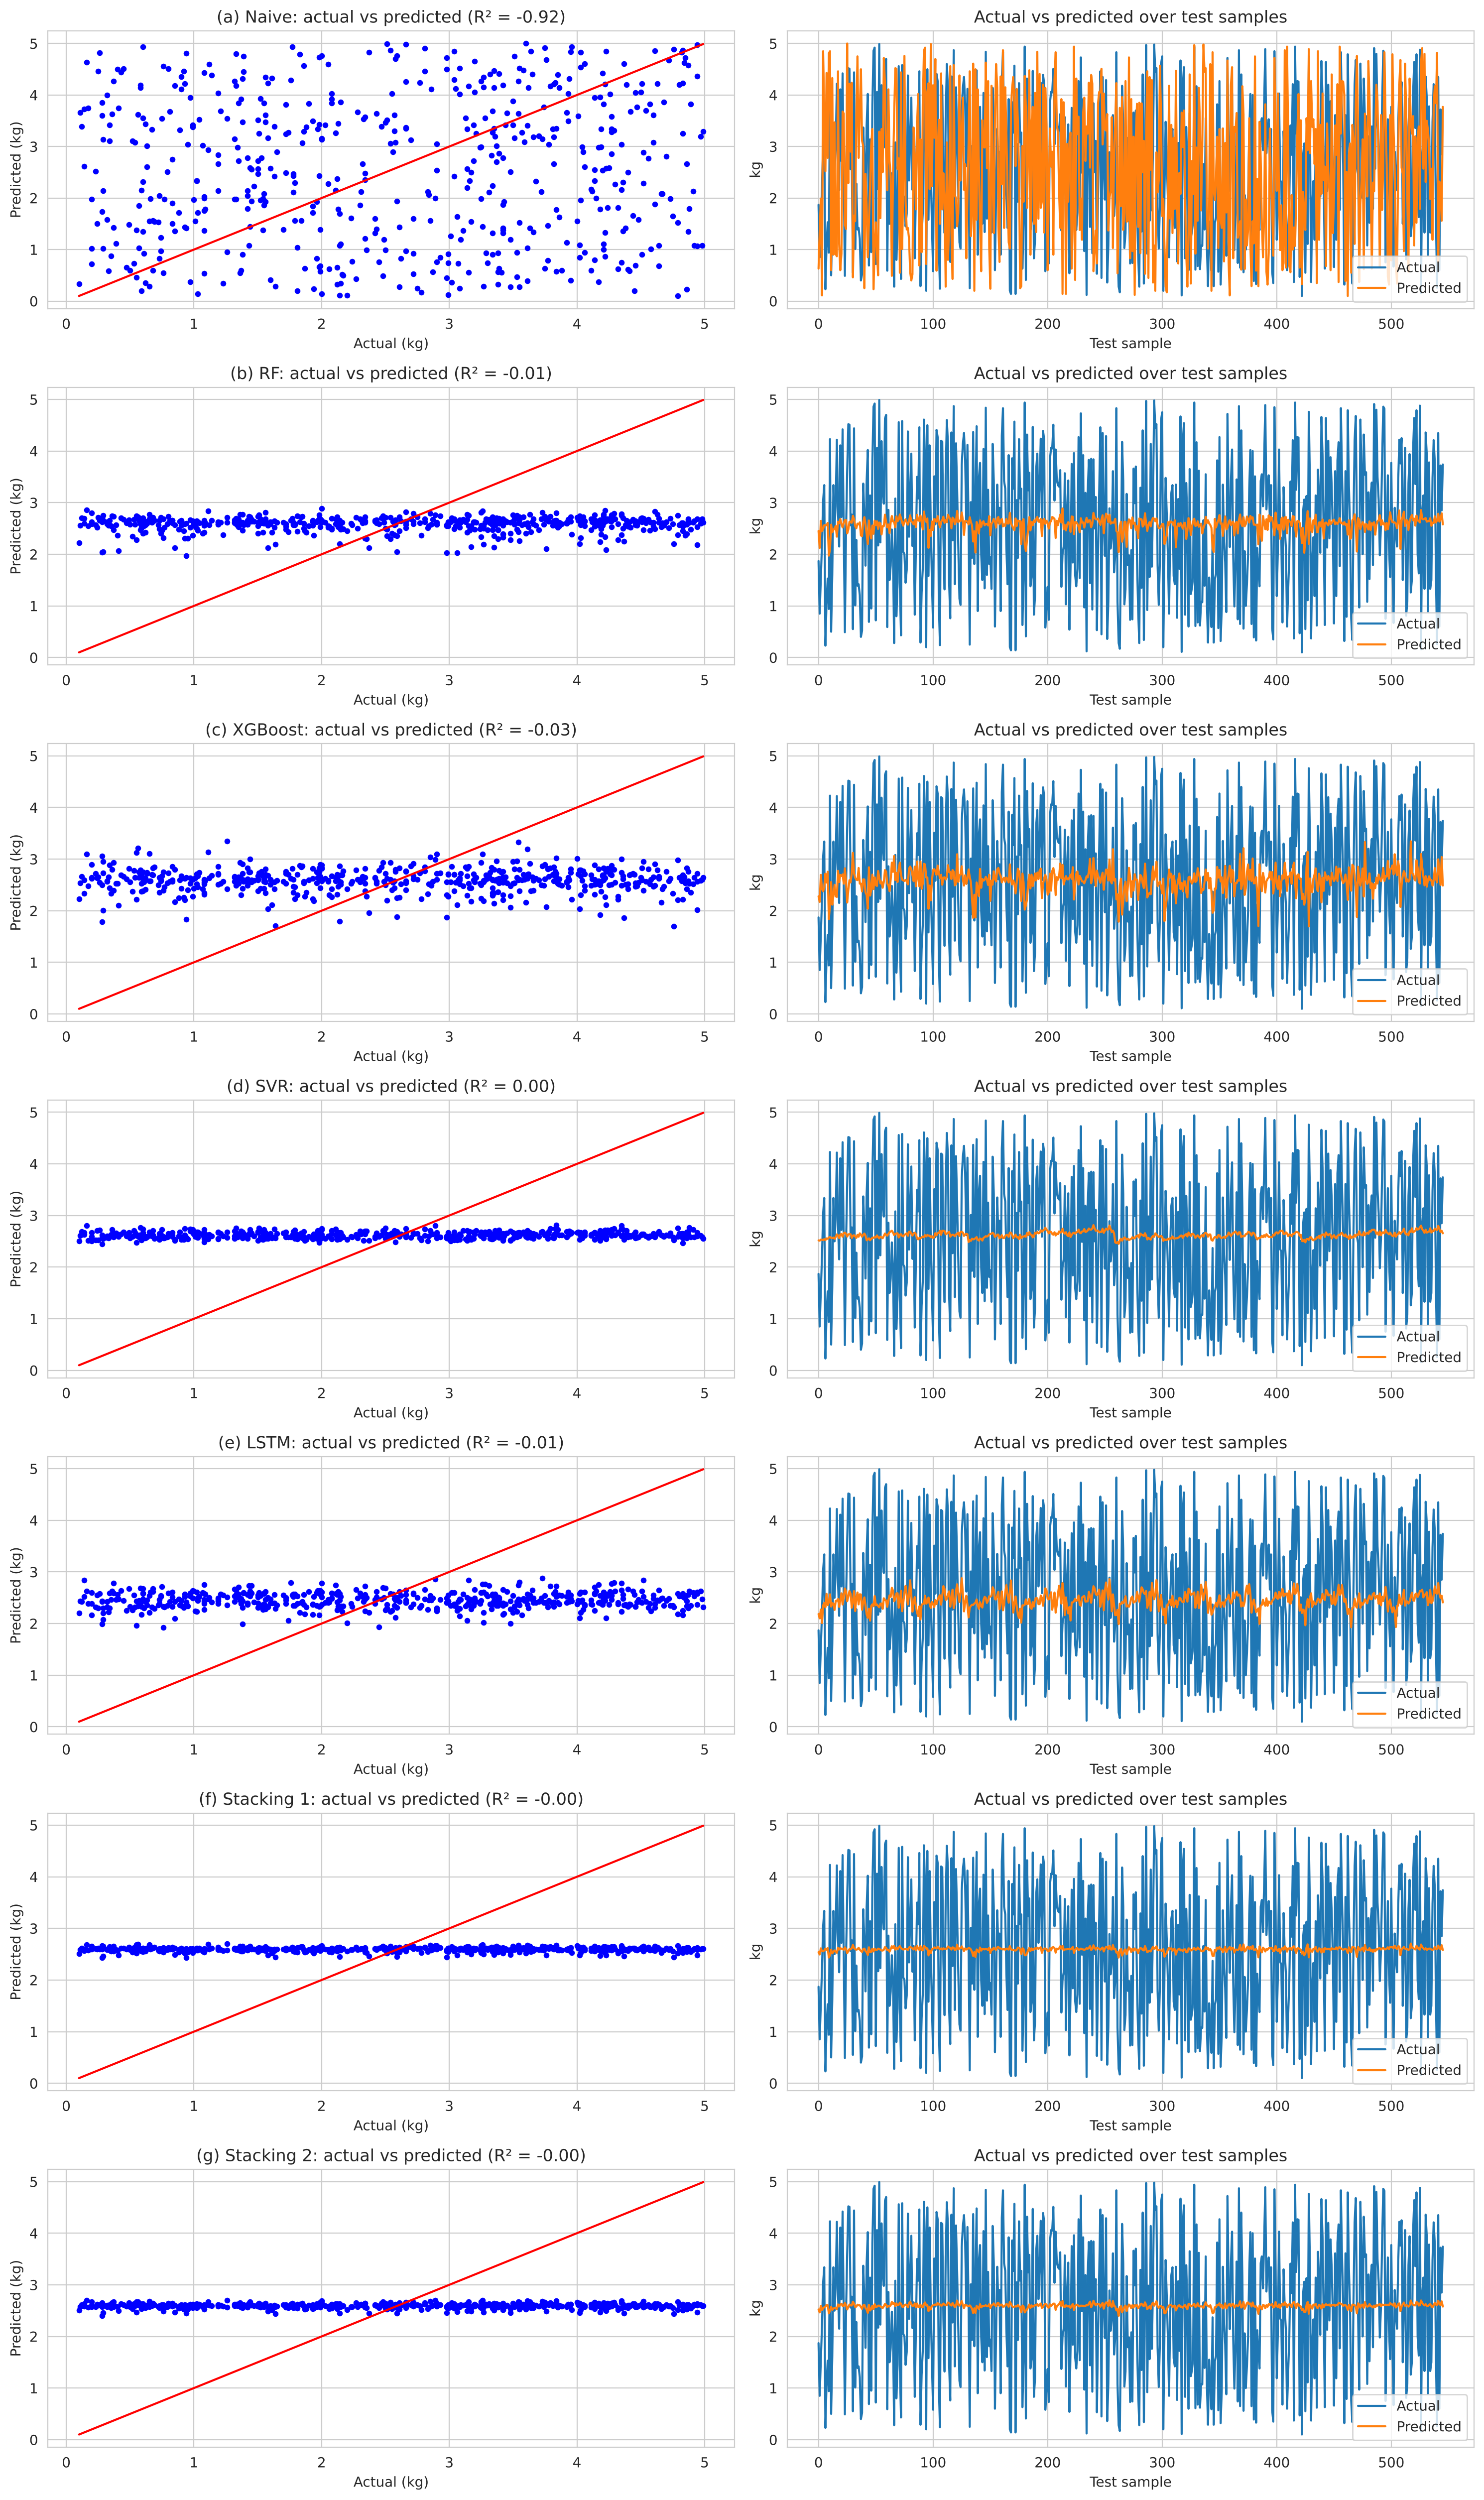

In [18]:
fig, axes = plt.subplots(len(preds), 2, figsize=(15, 3.6 * len(preds)))
for i, (name, p_) in enumerate(preds.items()):
    a = truth[name]; lims = [a.min(), a.max()]
    # Scatter of predicted vs actual with the identity line
    axes[i, 0].scatter(a, p_, s=10, c="blue"); axes[i, 0].plot(lims, lims, "r-")
    axes[i, 0].set(title=f"({'abcdefgh'[i]}) {name}: actual vs predicted (R² = {r2_score(a, p_):.2f})",   # CHANGED: more panel letters, because the baseline adds a row
                   xlabel=f"Actual ({UNIT})", ylabel=f"Predicted ({UNIT})")
    # Actual and predicted series over the test samples
    axes[i, 1].plot(a, label="Actual"); axes[i, 1].plot(p_, label="Predicted")
    axes[i, 1].set(title="Actual vs predicted over test samples", xlabel="Test sample", ylabel=UNIT); axes[i, 1].legend()
plt.tight_layout(); plt.show()

### Accuracy vs training time
R² (higher is better) and training time for each model, with the value labelled on each bar.

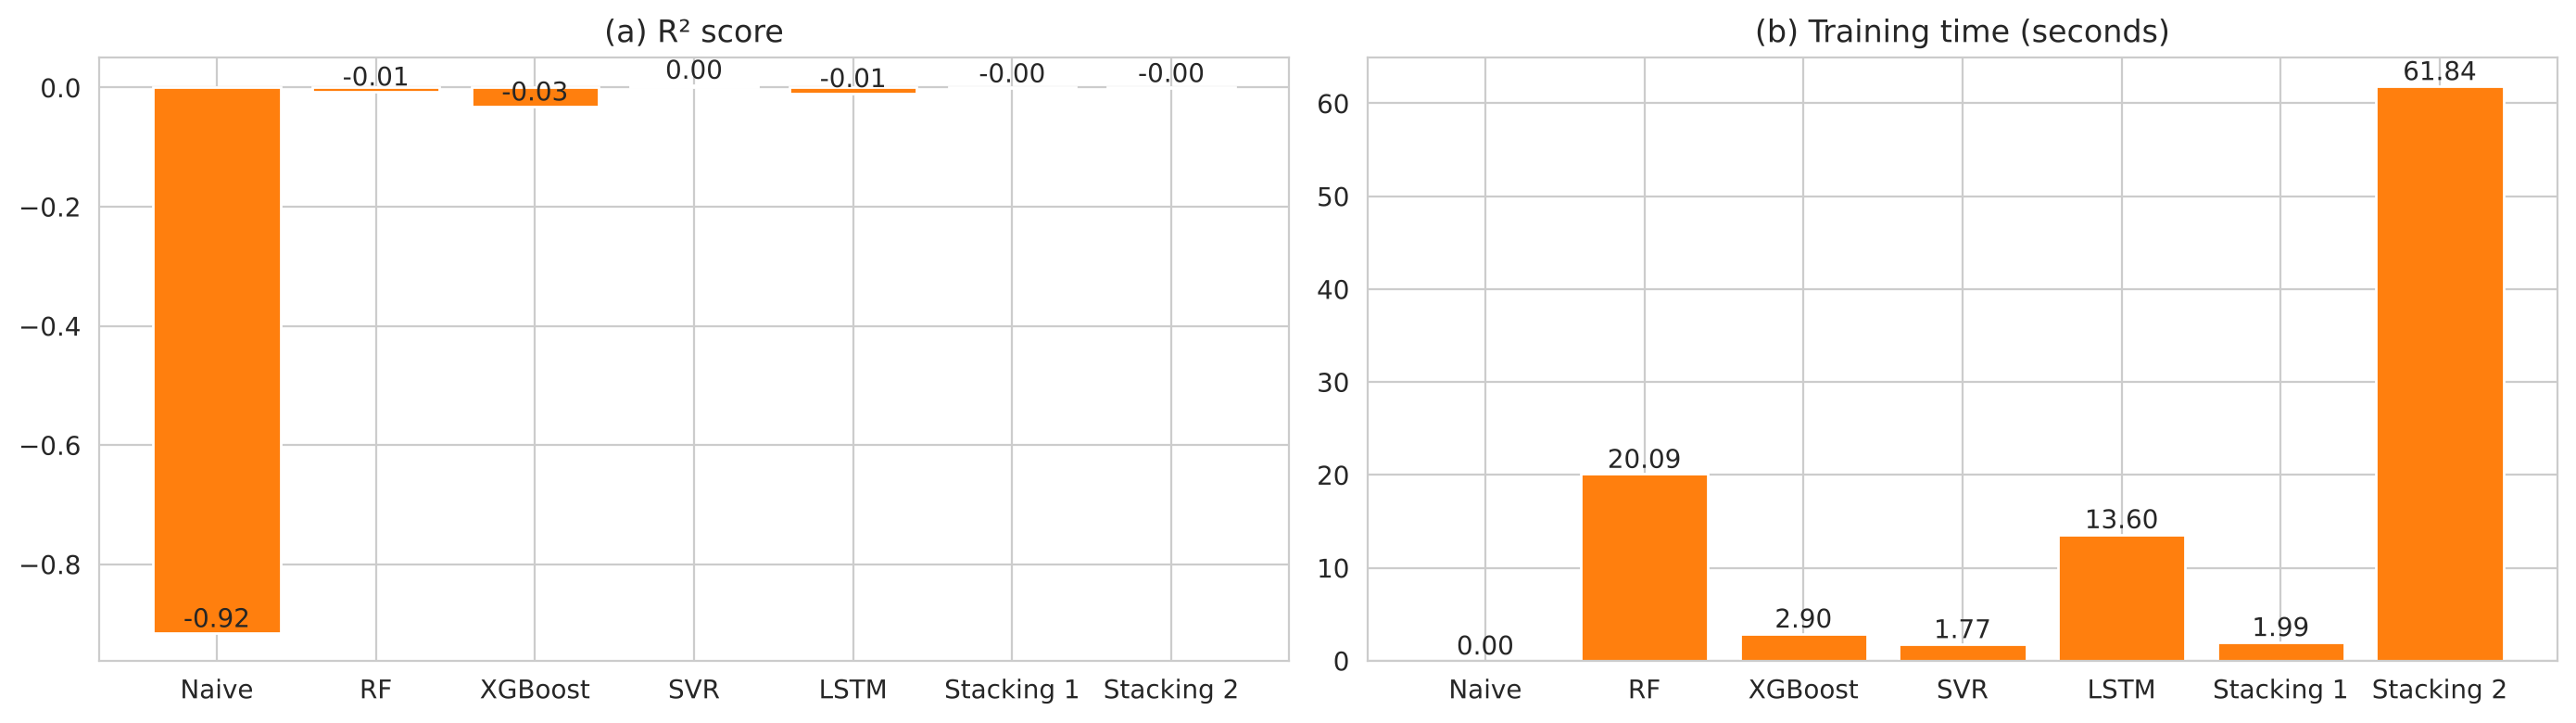

In [19]:
t = res.rename(index=lambda s: s.split(" (")[0])        # short model names for the x-axis
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, col, title in [(ax[0], "R2", "(a) R² score"), (ax[1], "Training time (s)", "(b) Training time (seconds)")]:
    a.bar(t.index, t[col], color="tab:orange"); a.set_title(title)
    for x, v in enumerate(t[col]): a.annotate(f"{v:.2f}", (x, v), ha="center", va="bottom")
plt.tight_layout(); plt.show()

## 11. Stacking training time vs accuracy
This section is new. Both stacks are trained again with the original way of choosing alpha: a 5-fold GridSearchCV around the whole stack, which retrains all base models for every alpha value. The base models, settings and folds are the same as in Sections 8 and 9, so the only difference is how alpha is chosen.

- Stacking time: time to train the stack, including choosing alpha (and, for Stacking 2, training its LSTM).
- Total time: stacking time plus the grid search and training of the base models the stack reuses (their training times in the results table).
- Stacking 2 is compared with its LSTM trained once in both rows, so the only difference is how alpha is chosen; the original tuning with an LSTM retrained in every fold would need about 156 LSTM trainings. The last row is the Stacking 2 of Section 9, whose LSTM is retrained in every fold.

Why the new method is faster: alpha only changes the Ridge step, and Ridge only sees the base models' out-of-fold predictions. The original grid search retrained every base model for each alpha value and fold (25 times plus a final fit), which gives the same base-model predictions every time. RidgeCV compares the same alpha values with the same MAE scoring directly on those predictions, so the base models are only trained once per fold.

alpha  \
Stack                                    Meta-learner tuning                               
Stacking 1                               Original: GridSearchCV around the stack  100.00   
                                         New: RidgeCV meta-learner                100.00   
Stacking 2, LSTM trained once            Original: GridSearchCV around the stack    0.10   
                                         New: RidgeCV meta-learner                  0.01   
Stacking 2, LSTM retrained in every fold New: RidgeCV meta-learner (Section 9)    100.00   

                                                                                    MAE  \
Stack                                    Meta-learner tuning                              
Stacking 1                               Original: GridSearchCV around the stack  1.216   
                                         New: RidgeCV meta-learner                1.216   
Stacking 2, LSTM trained once            Original: GridSearchCV around the stack  1.232   
                                         New: RidgeCV meta-learner                1.232   
Stacking 2, LSTM retrained in every fold New: RidgeCV meta-learner (Section 9)    1.215   

                                                                                   RMSE  \
Stack                                    Meta-learner tuning                              
Stacking 1                               Original: GridSearchCV around the stack  1.391   
                                         New: RidgeCV meta-learner                1.391   
Stacking 2, LSTM trained once            Original: GridSearchCV around the stack  1.409   
                                         New: RidgeCV meta-learner                1.409   
Stacking 2, LSTM retrained in every fold New: RidgeCV meta-learner (Section 9)    1.391   

                                                                                  SMAPE (%)  \
Stack                                    Meta-learner tuning                                  
Stacking 1                               Original: GridSearchCV around the stack     53.640   
                                         New: RidgeCV meta-learner                   53.640   
Stacking 2, LSTM trained once            Original: GridSearchCV around the stack     54.384   
                                         New: RidgeCV meta-learner                   54.390   
Stacking 2, LSTM retrained in every fold New: RidgeCV meta-learner (Section 9)       53.645   

                                                                                     R2  \
Stack                                    Meta-learner tuning                              
Stacking 1                               Original: GridSearchCV around the stack -0.001   
                                         New: RidgeCV meta-learner               -0.001   
Stacking 2, LSTM trained once            Original: GridSearchCV around the stack -0.028   
                                         New: RidgeCV meta-learner               -0.028   
Stacking 2, LSTM retrained in every fold New: RidgeCV meta-learner (Section 9)   -0.001   

                                                                                  Stacking time (s)  \
Stack                                    Meta-learner tuning                                          
Stacking 1                               Original: GridSearchCV around the stack             43.518   
                                         New: RidgeCV meta-learner                            1.990   
Stacking 2, LSTM trained once            Original: GridSearchCV around the stack             70.490   
                                         New: RidgeCV meta-learner                           16.922   
Stacking 2, LSTM retrained in every fold New: RidgeCV meta-learner (Section 9)               61.842   

                                                                                  Total time (s)  
Stack                                

Stacking 1: stacking time 43.5s -> 2.0s (21.9x faster), total 68.3s -> 26.7s, MAE 1.2 -> 1.2 (+0.00%)
Stacking 2, LSTM trained once: stacking time 70.5s -> 16.9s (4.2x faster), total 95.2s -> 41.7s, MAE 1.2 -> 1.2 (+0.01%)
Stacking 2, LSTM retrained in every fold (Section 9): stacking time 61.8s, total 86.6s, MAE 1.2


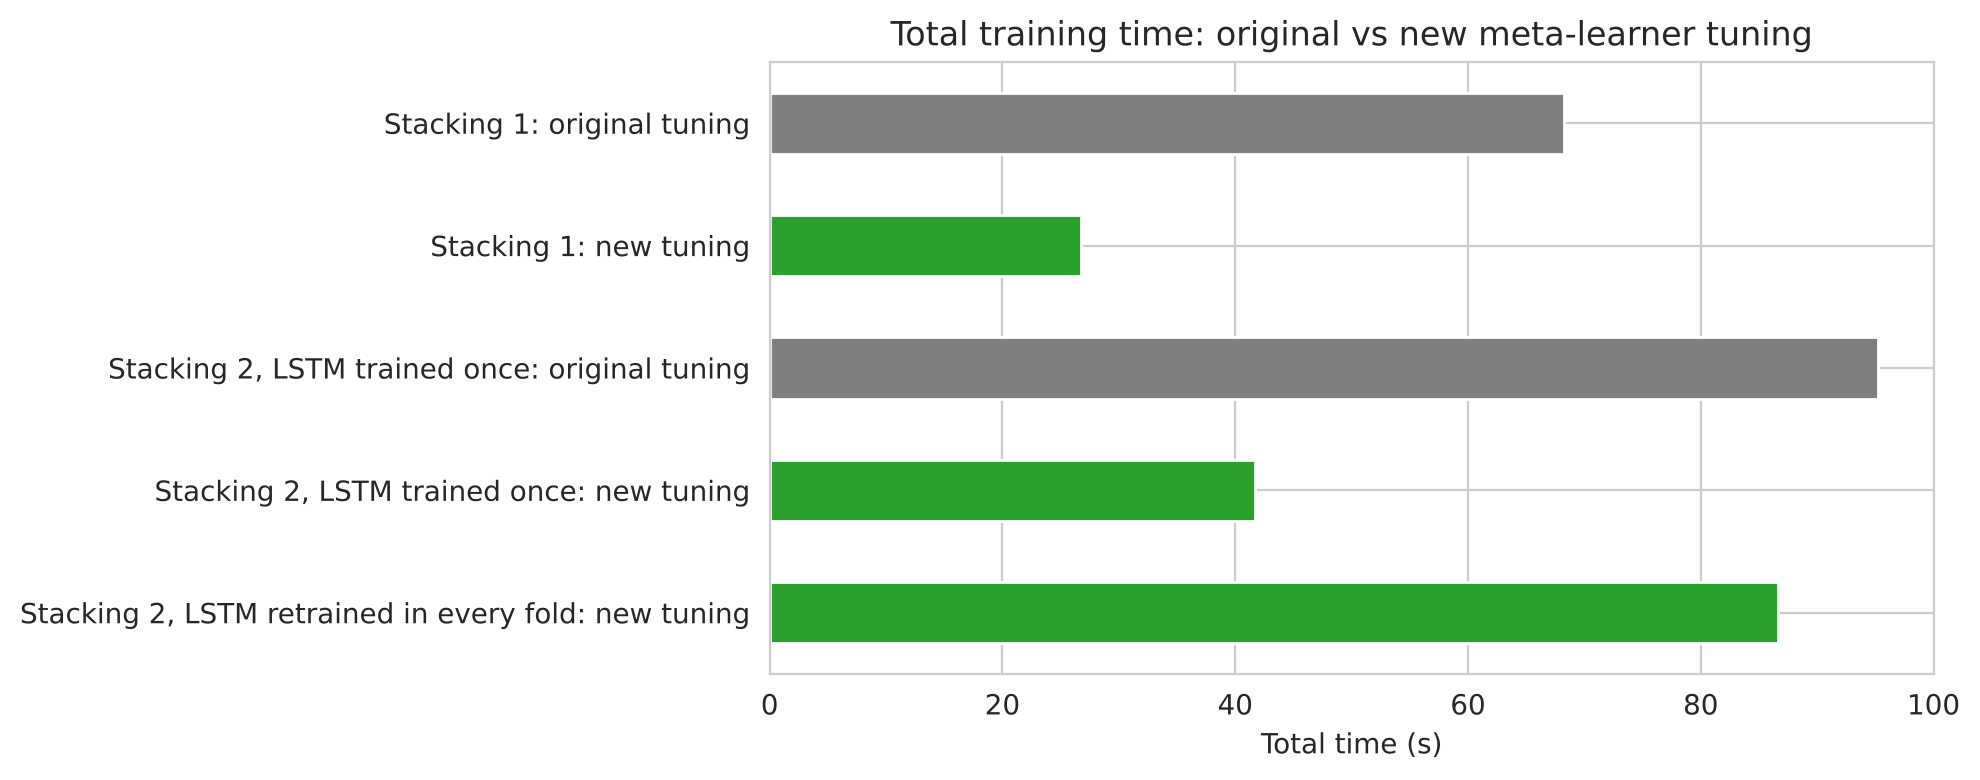

In [20]:
# CHANGED: new cell. Train both stacks with the original alpha tuning and compare with the new tuning
def original_tuning(estimators, X_fit):
    # Ridge meta-learner with alpha chosen by a GridSearchCV that retrains the whole stack for every alpha value
    stack = StackingRegressor(estimators=estimators, final_estimator=Ridge(), cv=CV_FOLDS, passthrough=False, n_jobs=-1)
    return GridSearchCV(stack, {"final_estimator__" + k: v for k, v in RIDGE_GRID.items()},
                        cv=CV_FOLDS, scoring=SCORING).fit(X_fit, y_tr)

base_secs = {r["Model"]: r["Training time (s)"] for r in results}                 # grid search and training time of each model
reuse = base_secs["RF"] + base_secs["XGBoost"] + base_secs["SVR"]                  # base-model time shared by both stacks

t0 = time.time()
o1 = original_tuning([("rf", best["RF"]), ("xgb", best["XGBoost"]), ("svr", best["SVR"])], X_tr)
o1_secs = time.time() - t0

# CHANGED: Stacking 2 is compared with its LSTM trained once in both rows, so only the alpha tuning differs
lstm_once = Pipeline([("window", ColumnSlice(p, None)), ("model", WindowLSTM(p, "stack2_once"))])
s2_once = [("rf", on_day(best["RF"])), ("xgb", on_day(best["XGBoost"])), ("svr", on_day(best["SVR"])), ("lstm", lstm_once)]

t0 = time.time()
PREFIT_LSTM["stack2_once"] = LSTMRegressor(p).fit(W_all[idx_tr], y_tr)          # the single LSTM training
with parallel_backend("threading"):
    o2 = original_tuning(s2_once, Z_tr)
o2_secs = time.time() - t0
o2_pred = o2.predict(Z_te)

t0 = time.time()
PREFIT_LSTM["stack2_once"] = LSTMRegressor(p).fit(W_all[idx_tr], y_tr)          # the single LSTM training
n2 = StackingRegressor(estimators=s2_once, final_estimator=RidgeCV(alphas=RIDGE_GRID["alpha"], scoring=SCORING),
                       cv=CV_FOLDS, passthrough=False, n_jobs=-1)
with parallel_backend("threading"):
    n2.fit(Z_tr, y_tr)
n2_secs = time.time() - t0
n2_pred = n2.predict(Z_te)

# One row per stack and tuning method: chosen alpha, accuracy and time
S2_ONCE, S2_REFIT = "Stacking 2, LSTM trained once", "Stacking 2, LSTM retrained in every fold"
rows = []
for stack_name, tuning, pred, secs_, alpha in [
        ("Stacking 1", "Original: GridSearchCV around the stack", o1.predict(X_te), o1_secs, o1.best_params_["final_estimator__alpha"]),
        ("Stacking 1", "New: RidgeCV meta-learner", preds["Stacking 1"], base_secs["Stacking 1 (RF, XGBoost, SVR)"], s1.final_estimator_.alpha_),
        (S2_ONCE, "Original: GridSearchCV around the stack", o2_pred, o2_secs, o2.best_params_["final_estimator__alpha"]),
        (S2_ONCE, "New: RidgeCV meta-learner", n2_pred, n2_secs, n2.final_estimator_.alpha_),
        (S2_REFIT, "New: RidgeCV meta-learner (Section 9)", preds["Stacking 2"], base_secs["Stacking 2 (RF, XGBoost, SVR, LSTM)"], s2.final_estimator_.alpha_)]:
    m = evaluate(stack_name, y_te, pred, secs_)
    rows.append({"Stack": stack_name, "Meta-learner tuning": tuning, "alpha": alpha,
                 "MAE": m["MAE"], "RMSE": m["RMSE"], "SMAPE (%)": m["SMAPE (%)"], "R2": m["R2"],
                 "Stacking time (s)": secs_, "Total time (s)": secs_ + reuse})
ro1 = pd.DataFrame(rows).set_index(["Stack", "Meta-learner tuning"])
display(ro1.round(3))

# Time saved and change in MAE for each stack
for s in ["Stacking 1", S2_ONCE]:
    old, new = ro1.loc[s].iloc[0], ro1.loc[s].iloc[1]
    print(f"{s}: stacking time {old['Stacking time (s)']:.1f}s -> {new['Stacking time (s)']:.1f}s "
          f"({old['Stacking time (s)'] / new['Stacking time (s)']:.1f}x faster), total {old['Total time (s)']:.1f}s -> {new['Total time (s)']:.1f}s, "
          f"MAE {old['MAE']:.1f} -> {new['MAE']:.1f} ({(new['MAE'] / old['MAE'] - 1) * 100:+.2f}%)")

refit = ro1.loc[S2_REFIT].iloc[0]
print(f"{S2_REFIT} (Section 9): stacking time {refit['Stacking time (s)']:.1f}s, total {refit['Total time (s)']:.1f}s, MAE {refit['MAE']:.1f}")

# Total training time of each stack and tuning method
labels = [f"{s}: {t.split(':')[0].lower()} tuning" for s, t in ro1.index]
ax = pd.Series(ro1["Total time (s)"].values, index=labels).plot(
    kind="barh", figsize=(10, 4), color=["tab:gray" if t.startswith("Original") else "tab:green" for _, t in ro1.index])
ax.invert_yaxis(); ax.set(xlabel="Total time (s)", title="Total training time: original vs new meta-learner tuning")
plt.tight_layout(); plt.show()

## 12. Explainability (SHAP and LIME)
This section is new. It explains the forecasts of both stacking ensembles. SHAP and LIME only use a model's predictions, so they explain each stack as a whole rather than its base models separately.

- SHAP splits each forecast into a contribution from every input. A positive contribution raises the forecast and a negative one lowers it. The contributions add up to the difference between that forecast and the average forecast over a reference sample of 100 training rows (the same rows for both stacks). SHAP is computed for `SHAP_ROWS` test rows chosen at random, to keep the run time manageable.
- The one-hot columns of each categorical input (for example the three `Meal` columns) are added together, so every original variable gets a single contribution.
- In Stacking 2 the LSTM's input is the window of the 10 previous records of the same series. SHAP treats the whole window as one input, called "LSTM window (previous 10 records)".
- LIME fits a simple linear model to a stack's predictions around one row and reports the inputs with the largest effect. It is used to check the SHAP explanations of two example rows. LIME's conditions refer to the scaled inputs (0 to 1). For Stacking 2, LIME keeps the 10-record window fixed at the row's own window and varies the other inputs.

In [21]:
# CHANGED: new cell. Install SHAP and LIME if they are missing (e.g. on Colab), then import them
import importlib.util
if importlib.util.find_spec("shap") is None or importlib.util.find_spec("lime") is None:
    !pip install -q shap lime
import shap
from lime.lime_tabular import LimeTabularExplainer

In [22]:
# CHANGED: new cell. SHAP values of both stacks for a random sample of test rows
WINDOW = "LSTM window (previous 10 records)"
W_flat = W_all.reshape(len(y), -1)

def s2_predict(M):
    # M holds the row features plus a row number; that row's 10-record window is looked up and passed to Stacking 2
    rows = np.clip(np.round(M[:, -1]).astype(int), 0, len(y) - 1)
    return s2.predict(np.hstack([M[:, :-1], W_flat[rows]]))

ex = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(idx_te), min(SHAP_ROWS, len(idx_te)), replace=False))   # explained test rows
MODELS = {
    "Stacking 1": {"predict": s1.predict, "X_tr": X_tr, "X_te": X_te[ex], "names": list(X.columns)},
    "Stacking 2": {"predict": s2_predict, "X_tr": np.column_stack([X_tr, idx_tr]), "X_te": np.column_stack([X_te, idx_te])[ex],
                   "names": list(X.columns) + [WINDOW]},
}
bg = np.random.RandomState(RANDOM_STATE).choice(len(idx_tr), 100, replace=False)   # the same 100 reference rows for both stacks

xai = {}
for name, m in MODELS.items():
    explainer = shap.PermutationExplainer(m["predict"], m["X_tr"][bg], feature_names=m["names"], seed=RANDOM_STATE)
    t0 = time.time()
    sv = explainer(m["X_te"])
    # Add the one-hot columns of each categorical input together, so each original variable has one contribution
    groups = {}
    for i, col in enumerate(m["names"]):
        groups.setdefault(next((c for c in CAT_COLS if col.startswith(c + "_")), col), []).append(i)
    var_shap = np.column_stack([sv.values[:, cols].sum(axis=1) for cols in groups.values()])
    xai[name] = {"sv": sv, "vars": list(groups), "shap": var_shap}
    # Check: base value + contributions should equal the stack's forecast for every explained test row
    gap = np.abs(sv.base_values + var_shap.sum(axis=1) - m["predict"](m["X_te"])).max()
    print(f"{name}: SHAP values for {len(m['X_te'])} test rows in {time.time() - t0:.1f}s | largest gap to the forecast {gap:.3f} {UNIT}")

PermutationExplainer explainer:   4%|▍         | 4/100 [00:00<?, ?it/s]

PermutationExplainer explainer:   6%|▌         | 6/100 [00:14<02:17,  1.46s/it]

PermutationExplainer explainer:   7%|▋         | 7/100 [00:17<03:21,  2.17s/it]

PermutationExplainer explainer:   8%|▊         | 8/100 [00:20<03:50,  2.51s/it]

PermutationExplainer explainer:   9%|▉         | 9/100 [00:23<04:05,  2.69s/it]

PermutationExplainer explainer:  10%|█         | 10/100 [00:26<04:22,  2.92s/it]

... (190 outputs left out)

PermutationExplainer explainer: 100%|██████████| 100/100 [10:16<00:00,  6.48s/it]

PermutationExplainer explainer: 101it [10:22,  6.39s/it]                         

PermutationExplainer explainer: 101it [10:22,  6.29s/it]

Stacking 2: SHAP values for 100 test rows in 622.5s | largest gap to the forecast 0.000 kg


### Global importance
Average size of each variable's contribution over the explained test rows (mean absolute SHAP value, in kg) and its share of the total, for both stacks. The beeswarm plots show the individual input columns: each dot is one test row, its position is the contribution and its colour is the input value (red = high, or category present). The LSTM window is left out of the Stacking 2 beeswarm because it has no single value to colour by.

Mean |SHAP| (kg)             Share (%)  \
                                        Stacking 1 Stacking 2 Stacking 1   
Waste_last_week                              0.013      0.012     19.683   
Waste_last_two_days                          0.013      0.011     18.880   
Waste_last_day                               0.011      0.010     16.795   
Meal                                         0.007      0.007     11.149   
Unit_Price_per_kg                            0.007      0.006     10.641   
Day_of_Week                                  0.006      0.005      9.186   
Canteen_Section                              0.005      0.004      7.001   
Weekend_Status                               0.003      0.002      3.941   
Food_Category                                0.002      0.002      2.724   
LSTM window (previous 10 records)            0.000      0.013      0.000   

                                              
                                  Stacking 2  
Waste_last_week                       16.432  
Waste_last_two_days                   15.833  
Waste_last_day                        14.010  
Meal                                   9.000  
Unit_Price_per_kg                      8.824  
Day_of_Week                            7.469  
Canteen_Section                        5.495  
Weekend_Status                         2.931  
Food_Category                          2.139  
LSTM window (previous 10 records)     17.864

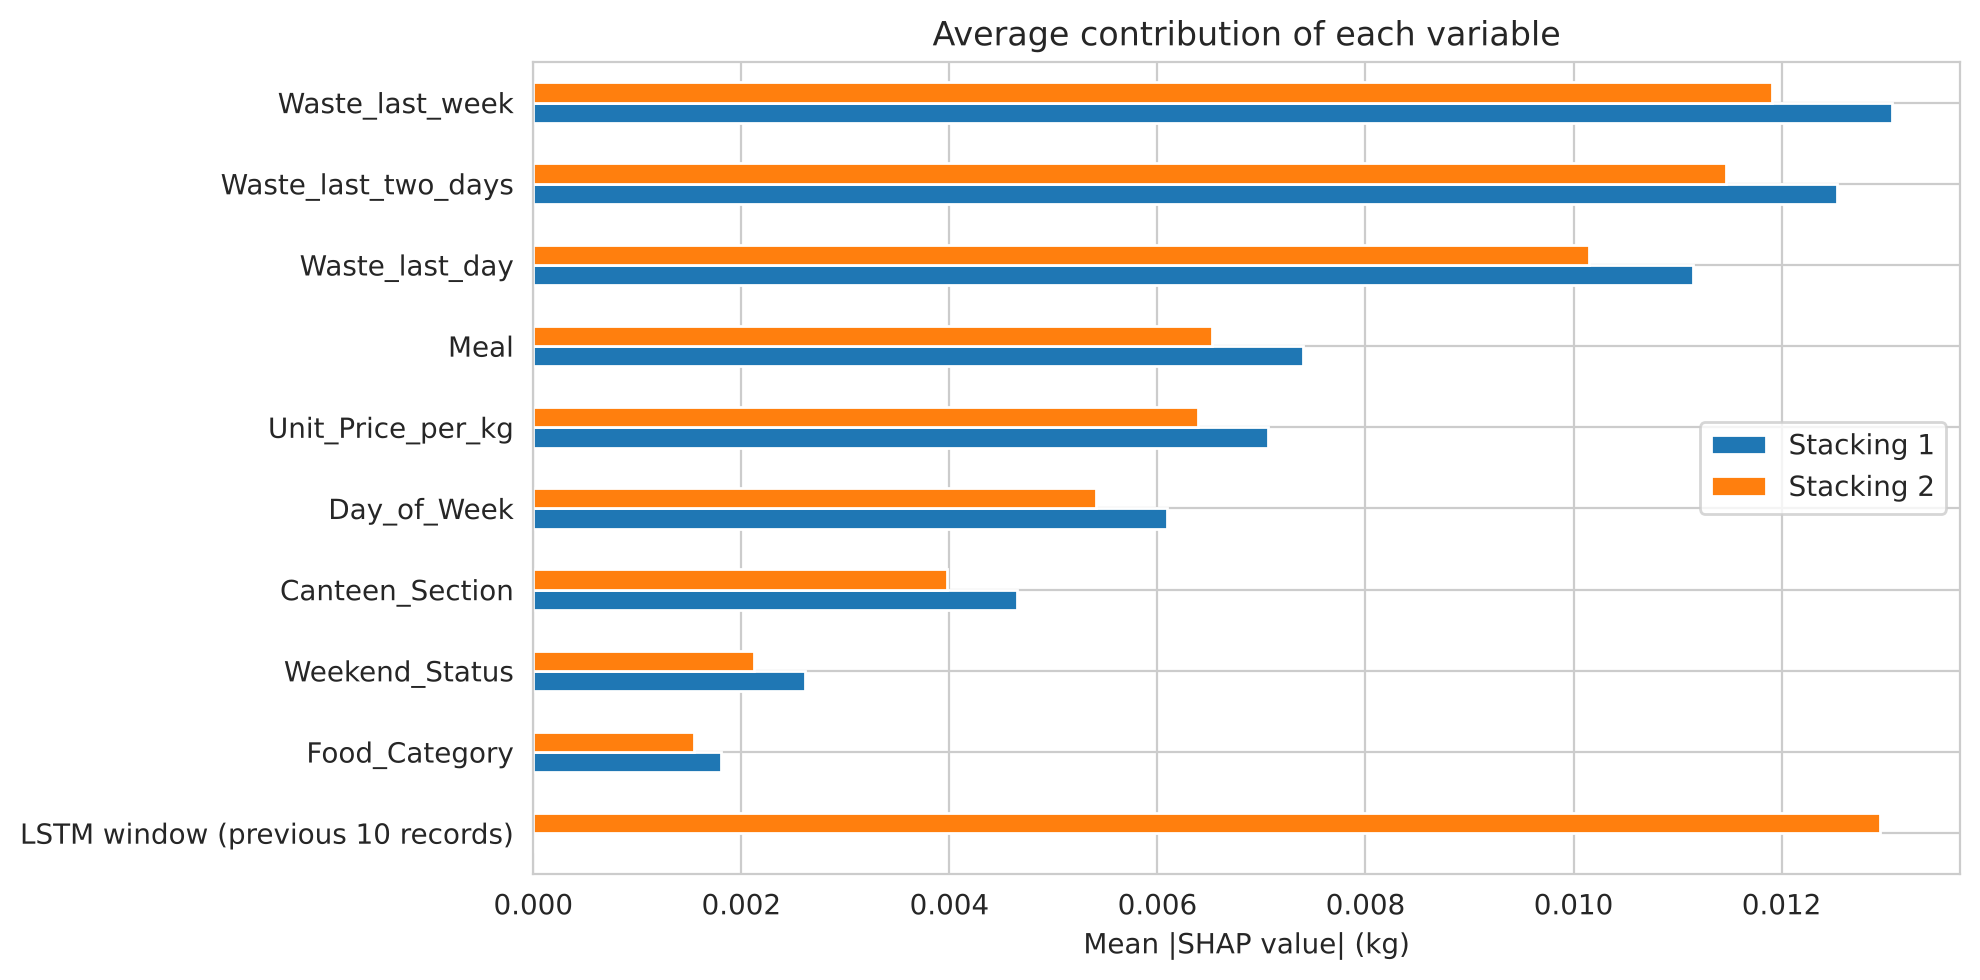

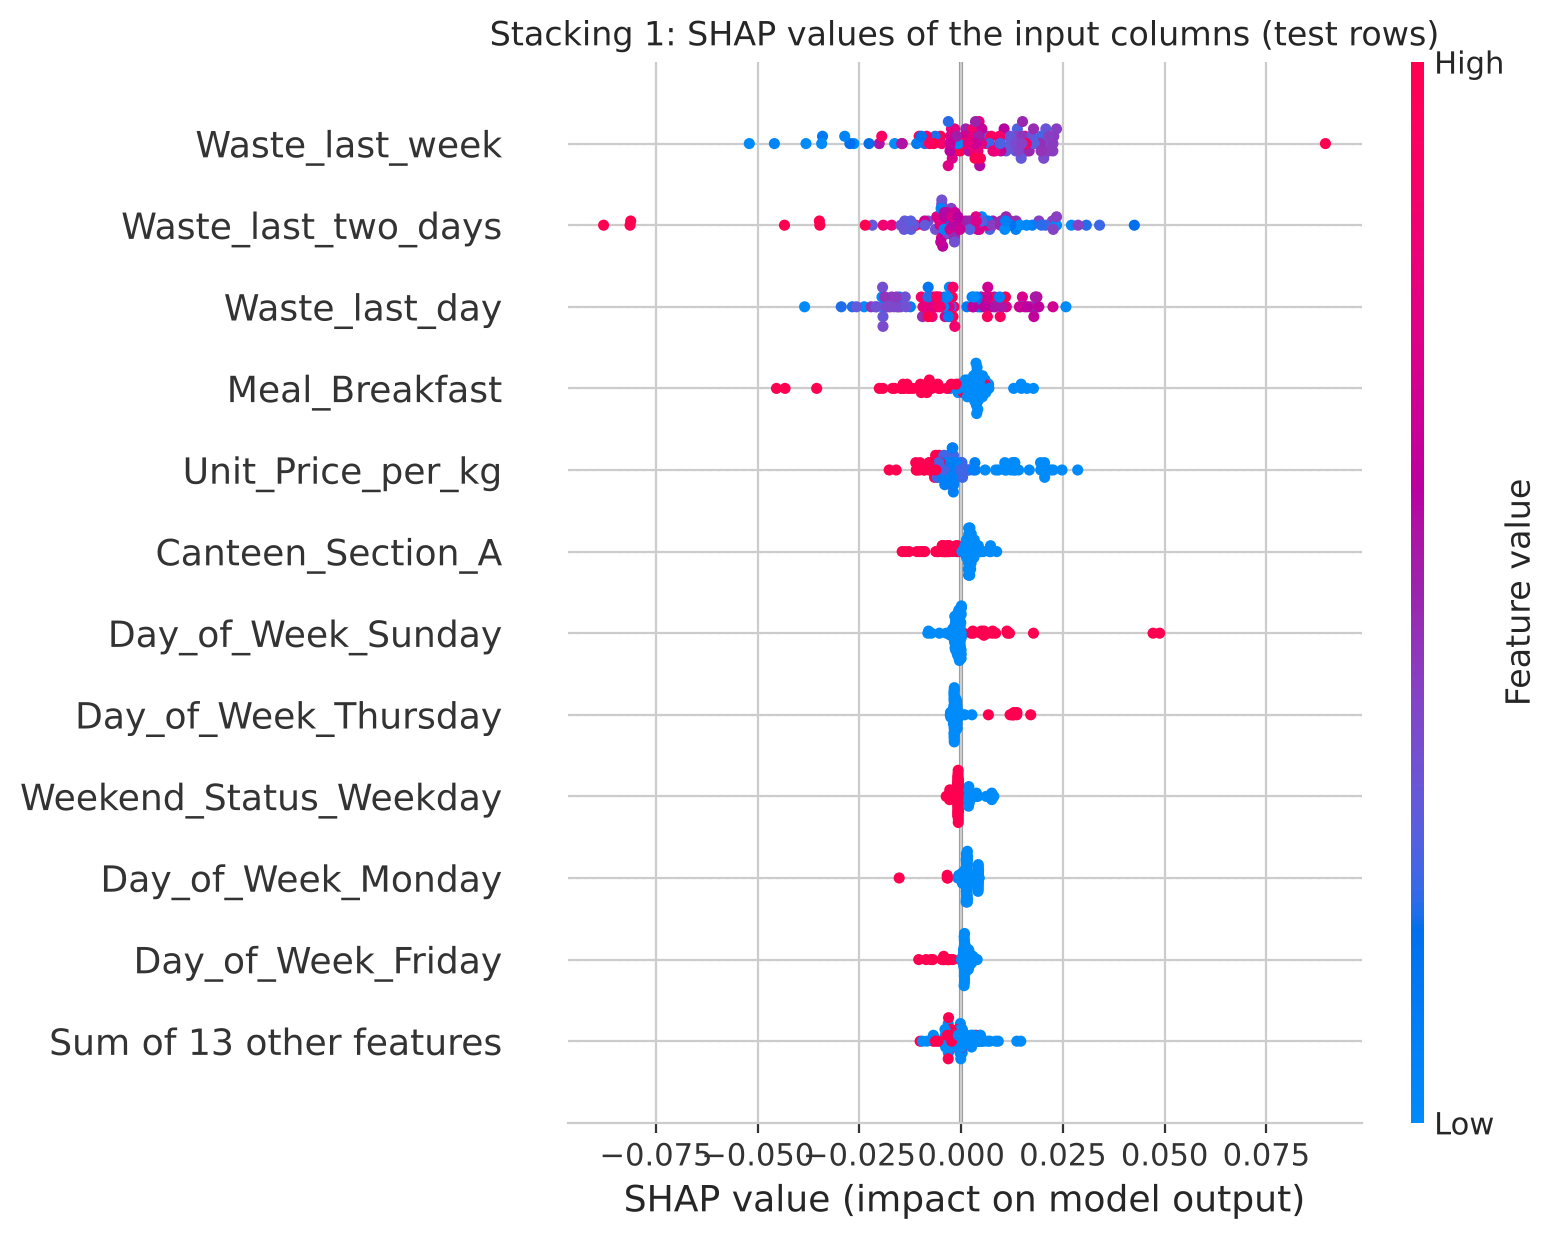

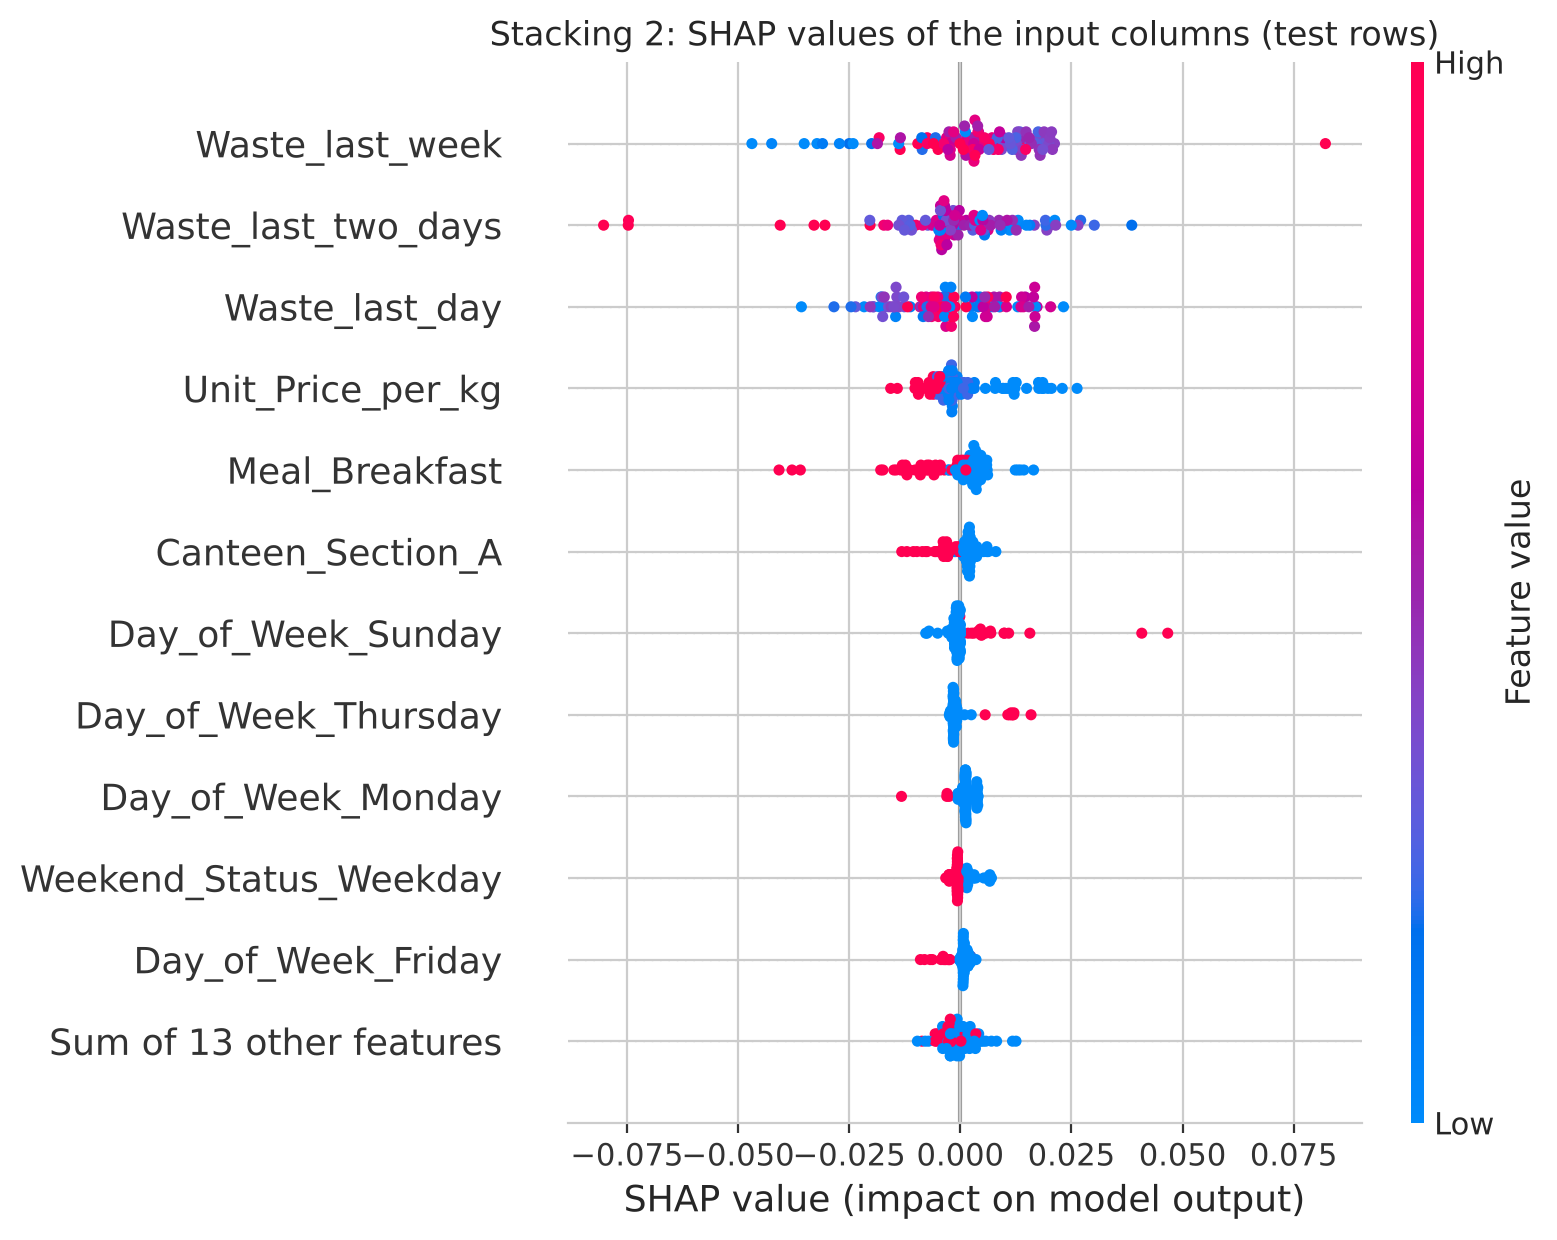

In [23]:
# CHANGED: new cell. Global importance of each original variable for both stacks
imp = pd.concat({name: pd.Series(np.abs(r["shap"]).mean(axis=0), index=r["vars"]) for name, r in xai.items()}, axis=1)
imp = imp.fillna(0).sort_values("Stacking 1", ascending=False)
table = pd.concat({f"Mean |SHAP| ({UNIT})": imp, "Share (%)": imp / imp.sum() * 100}, axis=1)
display(table.round(3))

ax = imp.iloc[::-1].plot(kind="barh", figsize=(10, 5), color=["tab:blue", "tab:orange"])
ax.set(xlabel=f"Mean |SHAP value| ({UNIT})", title="Average contribution of each variable")
plt.tight_layout(); plt.show()

for name, r in xai.items():
    cols = [i for i, n in enumerate(MODELS[name]["names"]) if n != WINDOW]
    shap.plots.beeswarm(r["sv"][:, cols], max_display=12, show=False)
    plt.title(f"{name}: SHAP values of the input columns (test rows)"); plt.tight_layout(); plt.show()

### Local explanations of two test rows
Two example rows are explained with both stacks: the explained test rows with the highest and the lowest Stacking 1 forecast. The waterfall plots start from the average forecast and add each variable's contribution to reach that row's forecast. The LIME tables list the conditions with the largest effect on the same forecasts, and the last line for each stack compares the three most important variables from both methods.

Highest forecast: 2025-08-10 (Sunday, Dinner, section A, Rice) | actual 1.26 kg


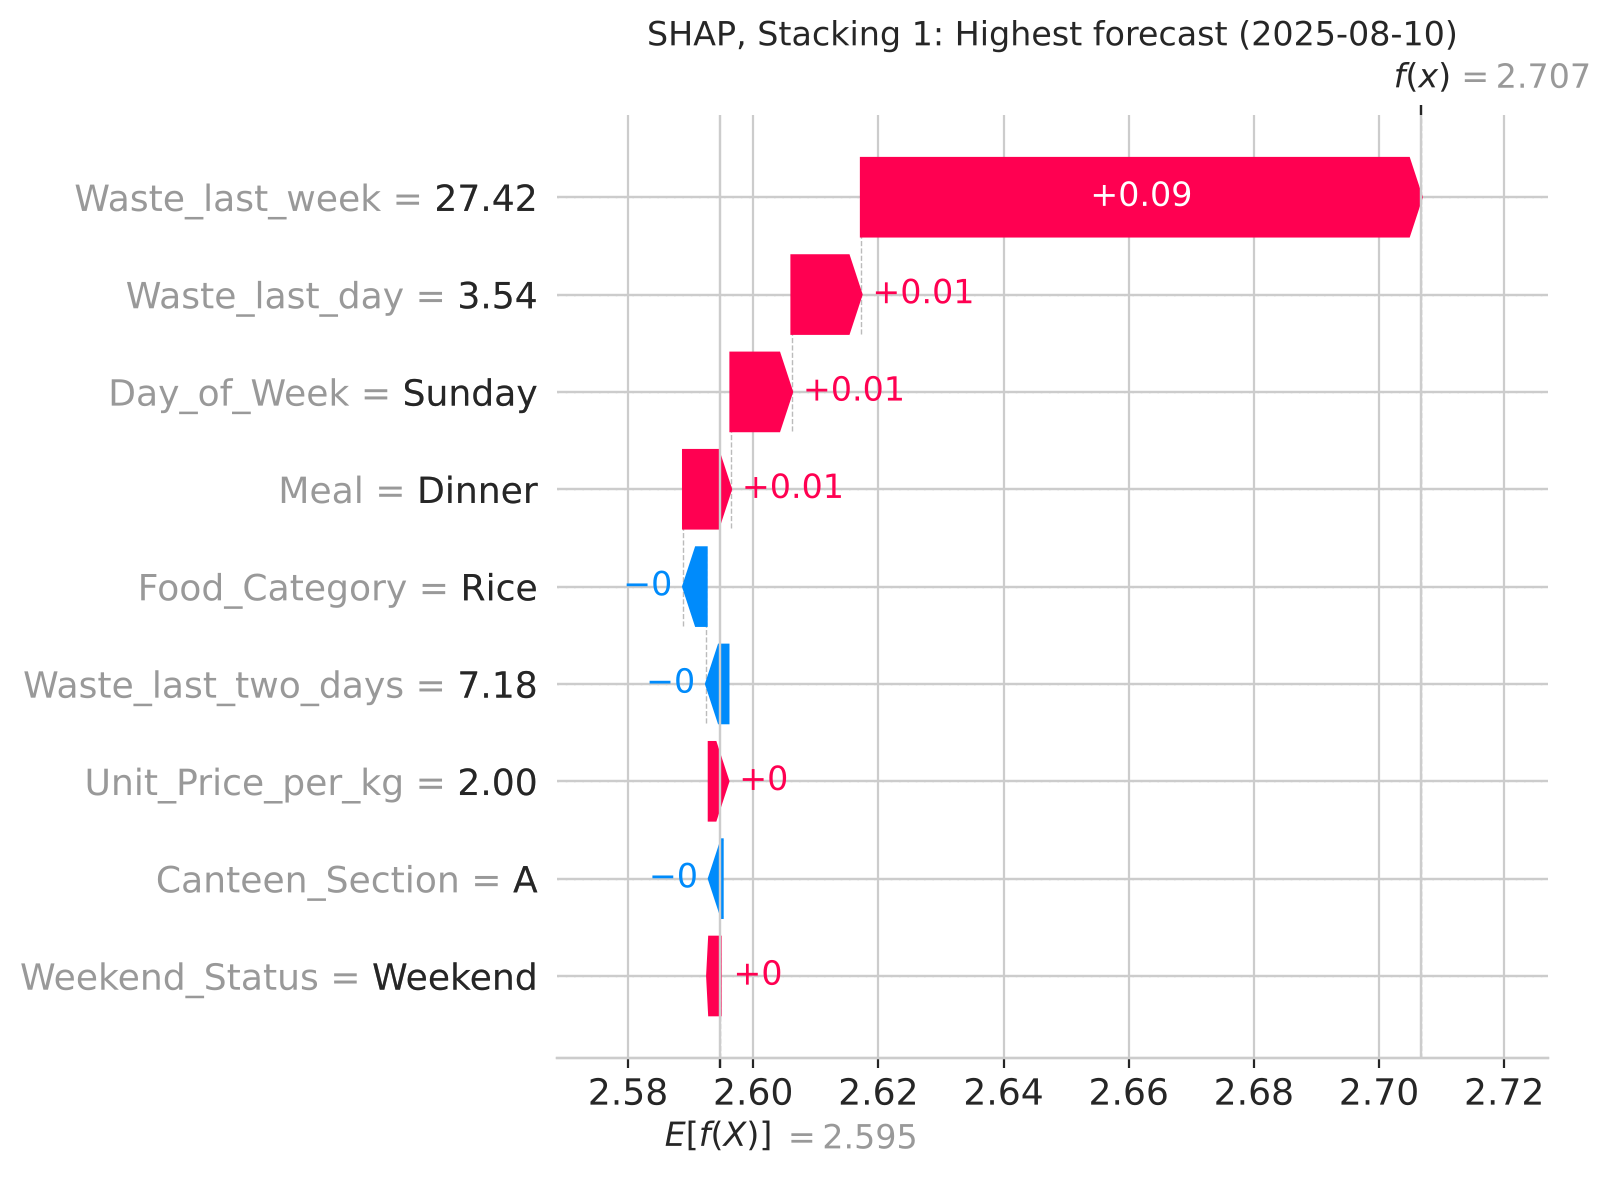

LIME, Stacking 1: Highest forecast | forecast 2.71 kg


,LIME condition (scaled inputs),Effect (kg)
0,Waste_last_two_days > 0.64,-0.02
1,Meal_Breakfast <= 0.00,0.02
2,Unit_Price_per_kg <= 0.08,0.01
3,Day_of_Week_Sunday > 0.00,0.01
4,0.51 < Waste_last_day <= 0.75,0.01
5,Day_of_Week_Thursday <= 0.00,-0.01
6,Weekend_Status_Weekday <= 0.00,0.01
7,Day_of_Week_Monday <= 0.00,0.01


Top 3 variables, Stacking 1 - SHAP: ['Waste_last_week', 'Waste_last_day', 'Day_of_Week'] | LIME: ['Waste_last_two_days', 'Meal', 'Unit_Price_per_kg']



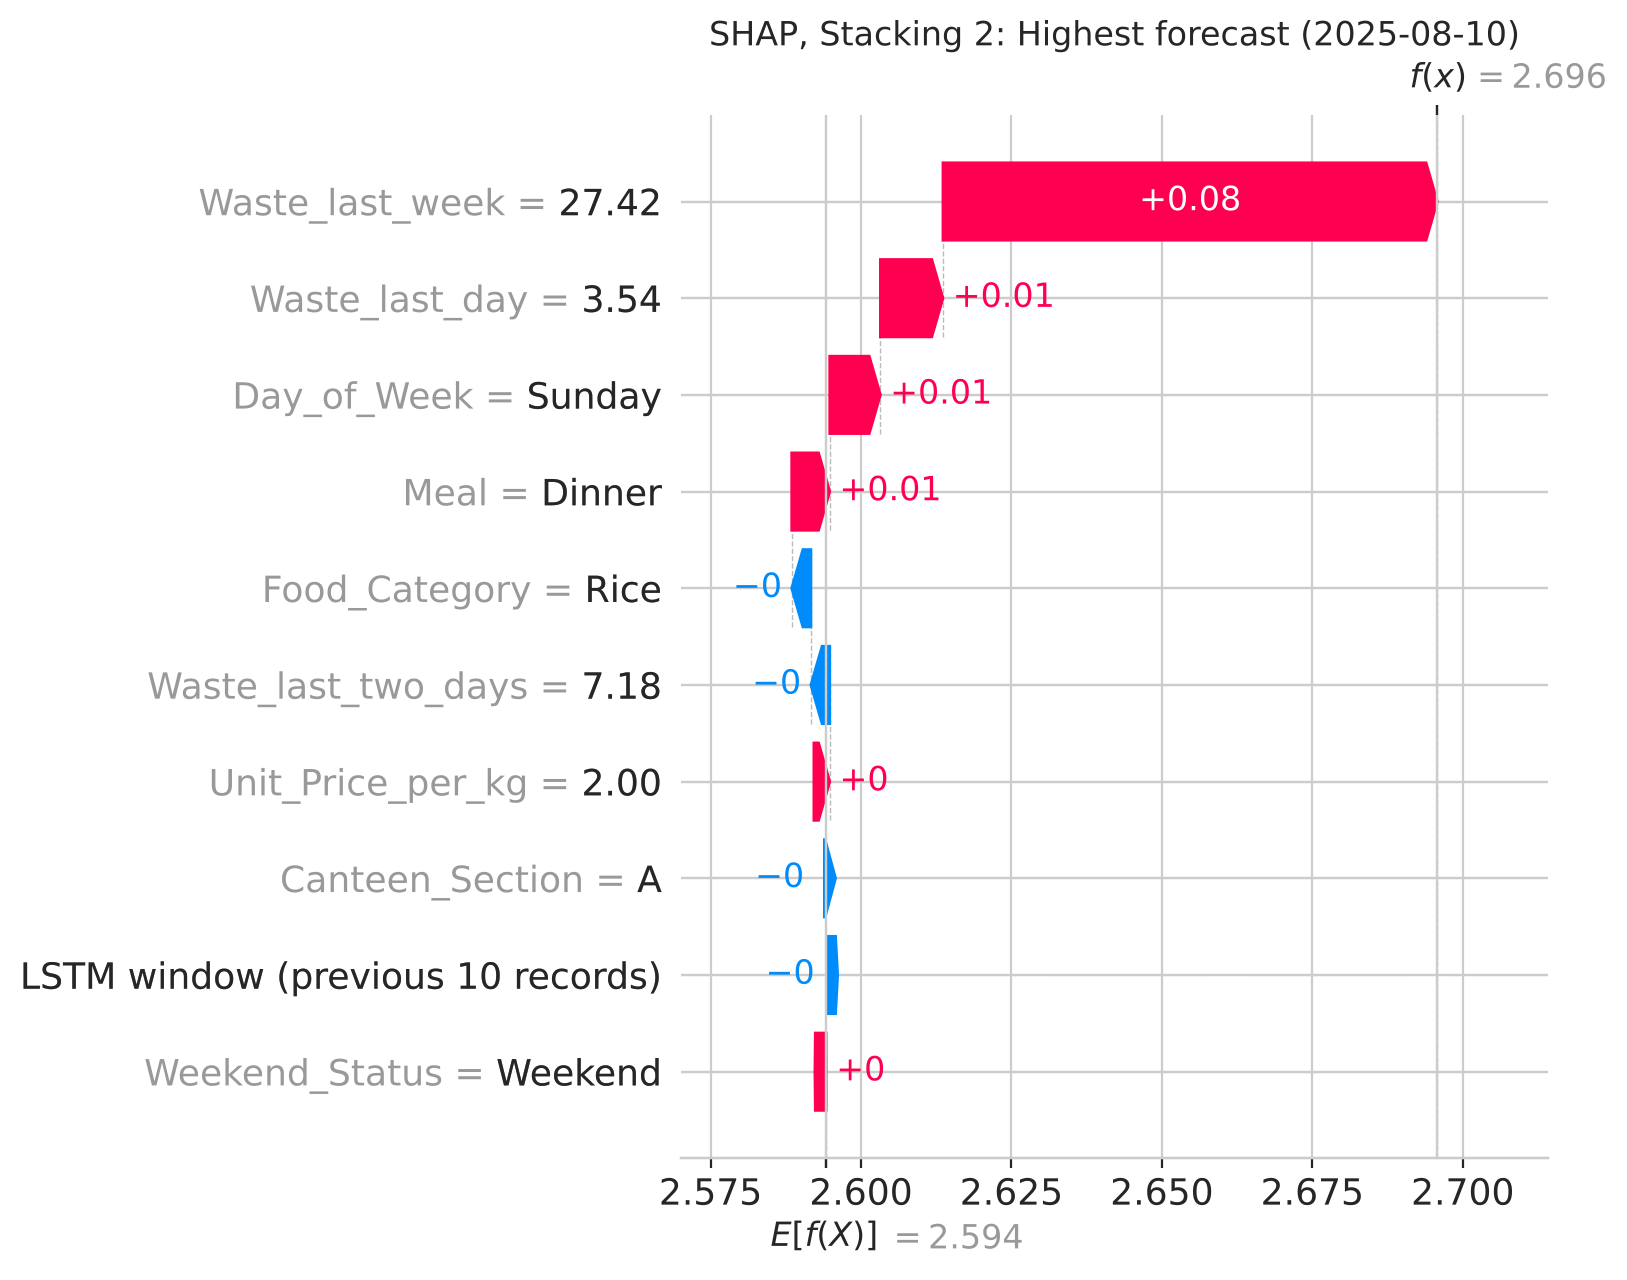

LIME, Stacking 2: Highest forecast | forecast 2.70 kg


,LIME condition (scaled inputs),Effect (kg)
0,Waste_last_two_days > 0.64,-0.02
1,Meal_Breakfast <= 0.00,0.01
2,Unit_Price_per_kg <= 0.08,0.01
3,Day_of_Week_Sunday > 0.00,0.01
4,0.51 < Waste_last_day <= 0.75,0.01
5,Day_of_Week_Thursday <= 0.00,-0.01
6,Day_of_Week_Friday <= 0.00,0.01
7,Weekend_Status_Weekday <= 0.00,0.01


Top 3 variables, Stacking 2 - SHAP: ['Waste_last_week', 'Waste_last_day', 'Day_of_Week'] | LIME: ['Waste_last_two_days', 'Meal', 'Unit_Price_per_kg']

Lowest forecast: 2025-07-29 (Tuesday, Breakfast, section C, Rice) | actual 0.94 kg


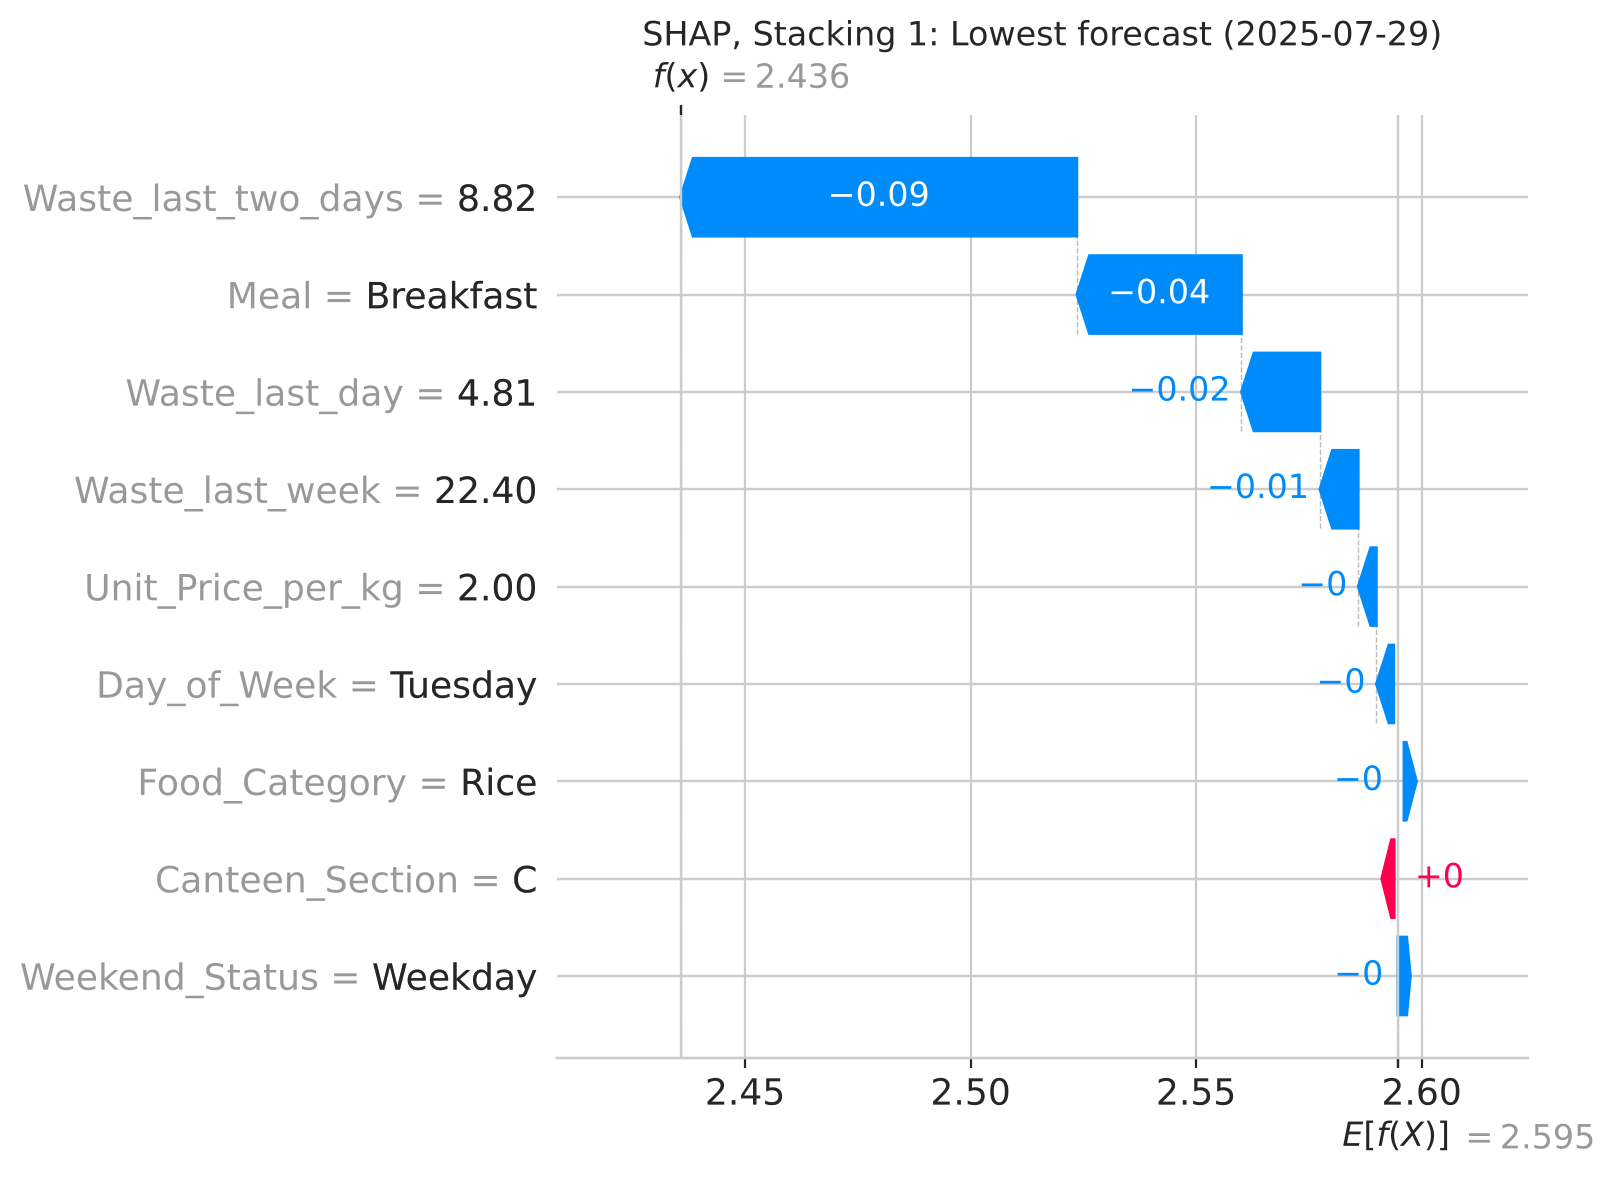

LIME, Stacking 1: Lowest forecast | forecast 2.44 kg


,LIME condition (scaled inputs),Effect (kg)
0,Waste_last_two_days > 0.64,-0.02
1,0.00 < Meal_Breakfast <= 1.00,-0.02
2,Unit_Price_per_kg <= 0.08,0.02
3,Day_of_Week_Sunday <= 0.00,-0.02
4,Day_of_Week_Thursday <= 0.00,-0.01
5,Canteen_Section_A <= 0.00,0.01
6,0.00 < Weekend_Status_Weekday <= 1.00,-0.01
7,Waste_last_day > 0.75,0.01


Top 3 variables, Stacking 1 - SHAP: ['Waste_last_two_days', 'Meal', 'Waste_last_day'] | LIME: ['Waste_last_two_days', 'Meal', 'Unit_Price_per_kg']



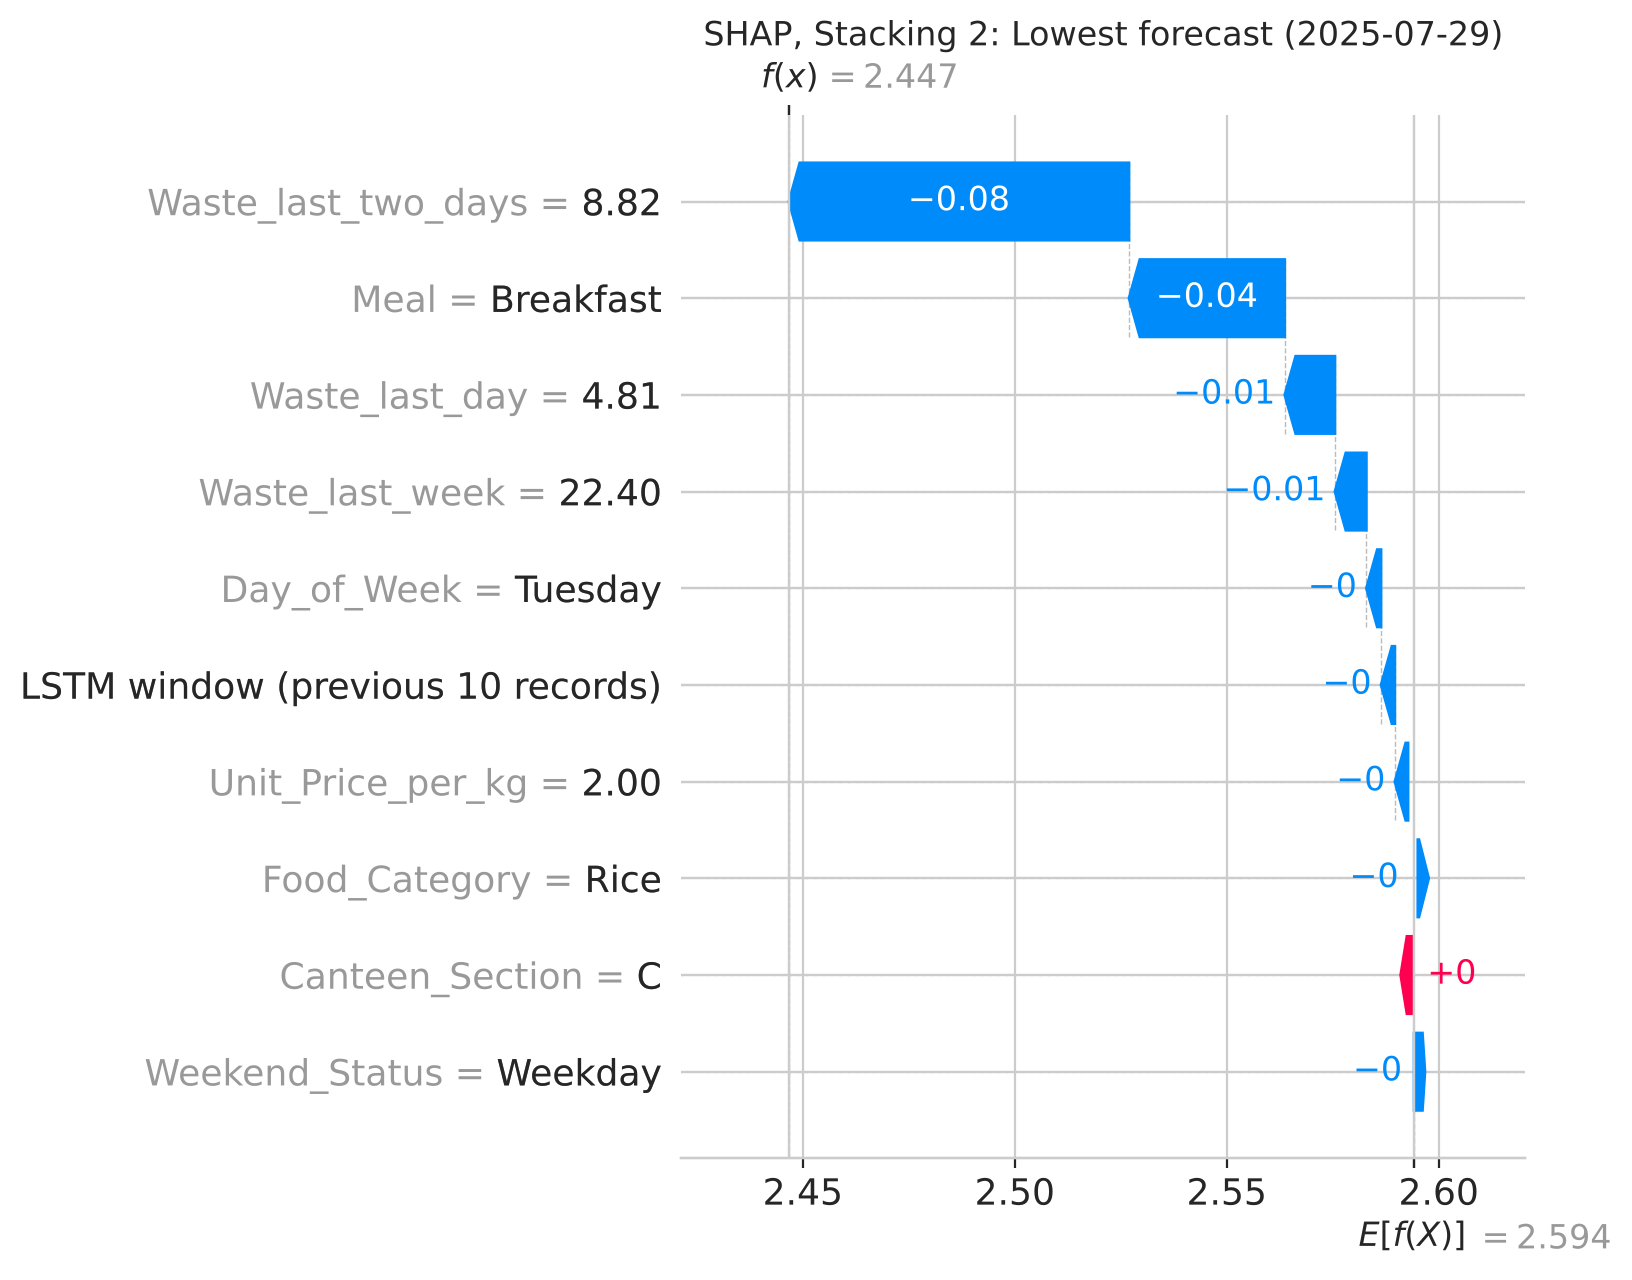

LIME, Stacking 2: Lowest forecast | forecast 2.45 kg


,LIME condition (scaled inputs),Effect (kg)
0,Waste_last_two_days > 0.64,-0.02
1,Unit_Price_per_kg <= 0.08,0.01
2,0.00 < Meal_Breakfast <= 1.00,-0.01
3,Day_of_Week_Sunday <= 0.00,-0.01
4,Day_of_Week_Thursday <= 0.00,-0.01
5,Waste_last_day > 0.75,0.01
6,Canteen_Section_A <= 0.00,0.01
7,0.00 < Weekend_Status_Weekday <= 1.00,-0.01


Top 3 variables, Stacking 2 - SHAP: ['Waste_last_two_days', 'Meal', 'Waste_last_day'] | LIME: ['Waste_last_two_days', 'Unit_Price_per_kg', 'Meal']



In [24]:
# CHANGED: new cell. SHAP waterfall plots and LIME explanations of two example test rows for both stacks
s1_ex = preds["Stacking 1"][ex]
examples = {"Highest forecast": int(np.argmax(s1_ex)), "Lowest forecast": int(np.argmin(s1_ex))}   # positions within the explained rows
lime_explainer = LimeTabularExplainer(X_tr, feature_names=list(X.columns), mode="regression", random_state=RANDOM_STATE)

def label(var, row):
    # Variable name with its original value in that row, for the plot labels
    if var == WINDOW:
        return var
    value = df[var].iloc[row] if var in CAT_COLS else X[var].iloc[row]
    return f"{var} = {value}" if var in CAT_COLS else f"{var} = {value:,.2f}"

for title, r in examples.items():
    t = ex[r]                       # position in the test set
    row = df.iloc[idx_te[t]]
    print(f"{title}: {row.Date.date()} ({row.Day_of_Week}, {row.Meal}, section {row.Canteen_Section}, {row.Food_Category}) | actual {y_te[t]:,.2f} {UNIT}")
    for name, res in xai.items():
        # SHAP waterfall with one bar per original variable
        exp = shap.Explanation(values=res["shap"][r], base_values=res["sv"].base_values[r],
                               feature_names=[label(v, idx_te[t]) for v in res["vars"]])
        shap.plots.waterfall(exp, max_display=10, show=False)
        plt.title(f"SHAP, {name}: {title} ({row.Date.date()})"); plt.tight_layout(); plt.show()

        # LIME around the same row (for Stacking 2 the 10-record window stays fixed at this row's window)
        if name == "Stacking 1":
            f = s1.predict
        else:
            f = lambda Xd, row_no=idx_te[t]: s2_predict(np.column_stack([Xd, np.full(len(Xd), row_no)]))
        lime_exp = lime_explainer.explain_instance(X_te[t], f, num_features=8)
        print(f"LIME, {name}: {title} | forecast {preds[name][t]:,.2f} {UNIT}")
        display(pd.DataFrame(lime_exp.as_list(), columns=["LIME condition (scaled inputs)", f"Effect ({UNIT})"]).round(2))

        # Compare the three most important variables from SHAP and LIME
        day_vars = [v for v in res["vars"] if v != WINDOW]
        shap_top = [str(v) for v in np.array(res["vars"])[np.argsort(-np.abs(res["shap"][r]))] if v != WINDOW][:3]
        lime_top = []
        for cond, _ in lime_exp.as_list():
            v = next((d for d in day_vars if d in cond), cond)
            if v not in lime_top: lime_top.append(v)
        print(f"Top 3 variables, {name} - SHAP: {shap_top} | LIME: {lime_top[:3]}\n")